# Effectiveness of thrombolysis in early (4 hr) arrivals with mild stroke: S-learner

**Good outcome = discharge mRS 0-2, or discharge mRS no worse than pre-stroke mRS**

An S-learner ("single learner") is one machine learning model that predicts outcome from patient characteristics *and* the treatment received. Treatment effects are estimated by asking the fitted model a counterfactual question: what would the predicted outcome be for this patient if they had not received thrombolysis? For the estimates to have a causal interpretation the model must include all confounders (factors that affect both outcome and the propensity to be treated), and there must be adequate overlap between treated and untreated patients with similar characteristics.

## Selection criteria

* Arrival within 4 hours of known stroke onset
* No thrombectomy
* Stroke type = infarction
* No recorded use of perfusion imaging
* Stroke severity (NIHSS) 1-5
* Thrombolysis, if given, given within 6 hours of onset
* Stroke team gave thrombolysis to at least 10 patients in the selected data

## Outcome

* Good outcome: discharge mRS 0-2, or discharge mRS <= pre-stroke mRS

## Treatment variable

* Onset-to-thrombolysis time (continuous; 'not given' coded with a sentinel value)

## Adjustment features

Prior disability, stroke severity, age, congestive heart failure, hypertension, diabetes, atrial fibrillation anticoagulant, any atrial fibrillation diagnosis (existing or new), stroke team, ethnicity.

## Notebook structure

1. **Set-up**: modules, settings, data selection, descriptive statistics, shared modelling functions.
2. **S-learner**: 5-fold cross-validated XGBoost model with hyperparameters tuned by cross-validation; out-of-fold counterfactual predictions for thrombolysed patients with thrombolysis removed.
3. **Benefit by patient characteristics and time**: mean benefit by feature value; regression of benefit on onset-to-thrombolysis time, overall and by NIHSS.
4. **Meta-model of benefit**: model of individual estimated benefit, with SHAP, to describe treatment-effect heterogeneity.
5. **Sensitivity analysis**: overlap, robustness to analytic choices, and unmeasured confounding.
6. **Commentary on results.**

*The model is fitted to all patients (thrombolysed and not); treatment effects are reported for thrombolysed patients.*

# Set-up

## Load modules

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
import statsmodels.api as sm
from IPython.display import display
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, log_loss, r2_score, roc_auc_score
from sklearn.model_selection import (
    KFold, StratifiedKFold, cross_val_predict, cross_validate,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier, XGBRegressor

# Suppress library warnings for cleaner output
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)


## Settings

* Thrombolysis not given is coded as `NO_TREATMENT` (99999 minutes). Because this is far beyond any real treatment time, the tree model can separate treated from untreated patients with a single split on the time feature. Setting the time to the sentinel is how the 'no thrombolysis' counterfactual is created.
* `POS_WEIGHT_FACTOR` is the manually chosen class-weight multiplier of the original specification (default XGBoost settings with class weighting). The primary analysis now uses tuned hyperparameters without class weighting; the original specification is kept as a sensitivity scenario.
* `N_TUNING_TRIALS`, `TUNING_TIMEOUT` and `TUNING_CV` control the Optuna hyperparameter search.

In [2]:
PREFIX = "mild_stroke_early_arrival_good_outcome_s_learner"
DATA_PATH = "../data/sam3/cleaned_data_anon_teams.csv"
OUTPUT_DIR = "./output"

MRS_TARGET = 2          # Good outcome: discharge mRS <= MRS_TARGET (or no worse than pre-stroke)
NO_TREATMENT = 99999    # Sentinel time meaning 'thrombolysis not given'
POS_WEIGHT_FACTOR = 1.15  # Original specification: multiplier for scale_pos_weight (neg/pos ratio x factor)
N_TUNING_TRIALS = 60      # Optuna trials (TPE sampler, median pruning)
TUNING_TIMEOUT = None     # Optional time limit for the search, in seconds (None = no limit)
TUNING_CV = 3             # Folds used to score each trial

N_SPLITS = 5
RANDOM_STATE = 42

TIME_THROMBOLYSIS = "onset_to_thrombolysis_time"

os.makedirs(OUTPUT_DIR, exist_ok=True)


def output_path(name):
    """Path for a saved output file, using the notebook prefix."""
    return f"{OUTPUT_DIR}/{PREFIX}_{name}"

## Features

Adjustment features are the measured confounders. Stroke team and ethnicity are categorical and are passed to XGBoost as pandas `category` columns (native categorical handling). Onset-to-thrombolysis time is the treatment feature.

In [3]:
ADJUSTMENT_FEATURES = [
    "prior_disability",
    "stroke_severity",
    "age",
    "congestive_heart_failure",
    "hypertension",
    "diabetes",
    "afib_anticoagulant",
    "any_afib_diagnosis",
]
CATEGORICAL_FEATURES = ["stroke_team", "ethnicity"]
NUMERIC_FEATURES = ADJUSTMENT_FEATURES + [TIME_THROMBOLYSIS]

X_FIELDS = NUMERIC_FEATURES + CATEGORICAL_FEATURES

## Load and select data

Selection steps, in order:

1. Remove patients with missing discharge mRS (outcome unknown).
2. Keep ischaemic stroke (infarction) only.
3. Keep arrivals within 4 hours of onset.
4. Exclude patients where perfusion imaging was used.
5. Exclude patients who received thrombectomy.
6. Keep mild stroke: NIHSS 1-5.
7. Keep stroke teams that thrombolysed at least 10 patients in this selection, so team effects can be estimated alongside thrombolysis.
8. Code missing thrombolysis time with the sentinel value; remove thrombolysis at 6 hours or later.

In [4]:
data = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Initial data shape: {data.shape}")

# Categorical features: label empty strings and use pandas 'category' dtype
for col in CATEGORICAL_FEATURES:
    data[col] = data[col].replace("", "Empty").astype("category")

# Numeric features: coerce non-numeric entries to NaN (XGBoost handles missing values)
for col in NUMERIC_FEATURES:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# 1-6: outcome known, infarction, arrival < 4 hrs, no perfusion imaging, no thrombectomy, NIHSS 1-5
data = data.dropna(subset=["discharge_disability"])
data = data[data["infarction"] == 1]
data = data[data["onset_to_arrival_time"] < 240]
data = data[data["perfusion_imaging_used"] == 0]
data = data[data["thrombectomy"] == 0]
data = data[data["stroke_severity"].between(1, 5)]
data["stroke_severity"] = data["stroke_severity"].astype(int)

# 7: teams with at least 10 thrombolysed patients (count of non-missing thrombolysis times)
thrombolysis_counts = data.groupby("stroke_team", observed=False)[TIME_THROMBOLYSIS].count()
data = data[data["stroke_team"].isin(thrombolysis_counts[thrombolysis_counts >= 10].index)]

# 8: missing time = not thrombolysed; thrombolysis must be within 6 hours
data[TIME_THROMBOLYSIS] = data[TIME_THROMBOLYSIS].fillna(NO_TREATMENT)
data = data[(data[TIME_THROMBOLYSIS] < 360) | (data[TIME_THROMBOLYSIS] == NO_TREATMENT)]

data["thrombolysis_given"] = (data[TIME_THROMBOLYSIS] != NO_TREATMENT).astype(int)

print(f"Final data shape: {data.shape}")
print(f"Thrombolysed: {data['thrombolysis_given'].sum()} "
      f"({data['thrombolysis_given'].mean():.1%})")

Initial data shape: (452863, 73)
Final data shape: (58387, 74)
Thrombolysed: 13378 (22.9%)


## Descriptive statistics: thrombolysed vs not thrombolysed

Thrombolysis time is summarised for treated patients only (the sentinel value is set to missing). The good outcome rate here is crude (unadjusted) and is shown for orientation only.

In [5]:
def good_outcome(df, mrs_target=MRS_TARGET, include_no_worse=True):
    """1 if discharge mRS <= target (or, optionally, no worse than pre-stroke mRS), else 0."""
    outcome = df["discharge_disability"] <= mrs_target
    if include_no_worse:
        outcome = outcome | (df["discharge_disability"] <= df["prior_disability"])
    return outcome.astype(int)


descriptive_data = data[ADJUSTMENT_FEATURES + [TIME_THROMBOLYSIS, "thrombolysis_given"]].copy()
descriptive_data[TIME_THROMBOLYSIS] = descriptive_data[TIME_THROMBOLYSIS].replace(NO_TREATMENT, np.nan)
descriptive_data["good_outcome"] = good_outcome(data)

descriptive_stats = (
    descriptive_data.groupby("thrombolysis_given")
    .agg(["mean", "std", "count"])
    .T
    .rename(columns={0: "not thrombolysed", 1: "thrombolysed"})
    .round(3)
)
descriptive_stats.to_csv(output_path("descriptive_stats.csv"))
descriptive_stats

thrombolysis_given                not thrombolysed  thrombolysed
prior_disability           mean              0.971         0.521
                           std               1.246         0.932
                           count         45009.000     13378.000
stroke_severity            mean              2.657         3.681
                           std               1.301         1.194
                           count         45009.000     13378.000
age                        mean             73.906        70.452
                           std              13.210        13.090
                           count         45009.000     13378.000
congestive_heart_failure   mean              0.057         0.035
                           std               0.232         0.184
                           count         45009.000     13378.000
hypertension               mean              0.565         0.512
                           std               0.496         0.500
                           count         45009.000     13378.000
diabetes                   mean              0.232         0.190
                           std               0.422         0.392
                           count         45009.000     13378.000
afib_anticoagulant         mean              0.187         0.023
                           std               0.390         0.149
                           count         45009.000     13378.000
any_afib_diagnosis         mean              0.249         0.123
                           std               0.432         0.328
                           count         45009.000     13378.000
onset_to_thrombolysis_time mean                NaN       177.309
                           std                 NaN        54.299
                           count             0.000     13378.000
good_outcome               mean              0.738         0.774
                           std               0.440         0.418
                           count         45009.000     13378.000

Thrombolysis use by NIHSS (treatment rate rises steeply with severity, a sign of strong selection into treatment):

In [6]:
pd.crosstab(data["stroke_severity"], data["thrombolysis_given"], margins=True).assign(
    proportion_thrombolysed=lambda t: (t[1] / t["All"]).round(3)
)

thrombolysis_given,0,1,All,proportion_thrombolysed
stroke_severity,,,,
1,10280,722,11002,0.066
2,12398,1747,14145,0.124
3,10071,2784,12855,0.217
4,7016,3951,10967,0.360
5,5244,4174,9418,0.443
All,45009,13378,58387,0.229


**Comment.** Thrombolysed patients (23%) differ systematically from those not thrombolysed:
* younger (mean 70 vs 74 years)
* less often previously disabled (mean pre-stroke mRS 0.5 vs 1.0)
* much less often on anticoagulants for AF (2% vs 19%, an expected contraindication)
* more severe strokes (mean NIHSS 3.7 vs 2.7)

Thrombolysis use rises from 7% at NIHSS 1 to 44% at NIHSS 5. Crude good-outcome rates are 77% vs 74%. The S-learner adjusts for the measured differences, but the strong selection by severity shows that clinical judgement drives treatment, and part of that judgement (e.g. whether the deficit is disabling) is not recorded.

## Shared modelling functions

* `split_folds`: stratified k-fold split (stratified on outcome). Every patient appears in exactly one test fold.
* `xgb_factory`: returns a function that builds an XGBoost classifier for a training fold, with optional class weighting.
* `train_and_evaluate`: fits one model per fold and reports out-of-fold AUC, balanced accuracy, observed and predicted positive rate, and mean predicted probability (a basic calibration-in-the-large check).
* `to_log_odds`: converts probabilities to log-odds after clipping to avoid infinite values.
* `predict_thrombolysis_counterfactuals`: for thrombolysed patients in each held-out fold, predicts outcome with actual thrombolysis and with thrombolysis removed.
* `tune_xgb`: Optuna (TPE sampler) search over XGBoost hyperparameters, scored by cross-validated log loss, with unpromising trials pruned early (see S-learner method notes).

In [7]:
def split_folds(X, y, n_splits=N_SPLITS, random_state=RANDOM_STATE):
    """Return a list of (train_X, test_X, train_y, test_y) for stratified k-fold splits."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    return [
        (X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx])
        for train_idx, test_idx in skf.split(X, y)
    ]


def xgb_factory(pos_weight_factor=None, **xgb_params):
    """
    Return a function that builds an XGBoost classifier for a training fold.

    If pos_weight_factor is given, scale_pos_weight = (negatives / positives) x factor;
    otherwise no class weighting is used.
    """
    def make_model(train_y):
        weight = 1.0
        if pos_weight_factor is not None:
            positives = train_y.sum()
            weight = (len(train_y) - positives) / positives * pos_weight_factor
        return XGBClassifier(
            enable_categorical=True,
            verbosity=0,
            random_state=RANDOM_STATE,
            eval_metric="logloss",
            scale_pos_weight=weight,
            **xgb_params,
        )
    return make_model


def train_and_evaluate(folds, model_factory):
    """Fit one model per fold; return the models and a table of out-of-fold performance."""
    models, results = [], []
    for split, (train_X, test_X, train_y, test_y) in enumerate(folds, start=1):
        model = model_factory(train_y)
        model.fit(train_X, train_y)
        probabilities = model.predict_proba(test_X)[:, 1]
        predictions = model.predict(test_X)
        models.append(model)
        results.append({
            "split": split,
            "AUC": roc_auc_score(test_y, probabilities),
            "balanced_accuracy": balanced_accuracy_score(test_y, predictions),
            "actual_positive_rate": test_y.mean(),
            "predicted_positive_rate": predictions.mean(),
            "mean_predicted_probability": probabilities.mean(),
        })
    return models, pd.DataFrame(results).set_index("split").round(4)


def to_log_odds(probabilities, eps=1e-9):
    """Convert probabilities to log-odds, clipping to avoid infinite values."""
    p = np.clip(probabilities, eps, 1 - eps)
    return np.log(p / (1 - p))


def predict_thrombolysis_counterfactuals(models, folds):
    """Out-of-fold predictions for thrombolysed patients, with and without thrombolysis."""
    frames = []
    for model, (_, test_X, _, test_y) in zip(models, folds):
        treated = test_X[TIME_THROMBOLYSIS] < NO_TREATMENT
        treated_X = test_X[treated]

        fold_cf = treated_X.copy()
        fold_cf.insert(0, "patient_index", treated_X.index)
        fold_cf["actual_y"] = test_y[treated]
        fold_cf["y_prob_treated"] = model.predict_proba(treated_X)[:, 1]
        fold_cf["y_prob_no_thrombolysis"] = model.predict_proba(
            treated_X.assign(**{TIME_THROMBOLYSIS: NO_TREATMENT})
        )[:, 1]
        frames.append(fold_cf)

    cf = pd.concat(frames, ignore_index=True)
    cf["treatment_diff_prob"] = cf["y_prob_treated"] - cf["y_prob_no_thrombolysis"]
    cf["log_odds_treated"] = to_log_odds(cf["y_prob_treated"])
    cf["log_odds_no_thrombolysis"] = to_log_odds(cf["y_prob_no_thrombolysis"])
    cf["log_odds_diff"] = cf["log_odds_treated"] - cf["log_odds_no_thrombolysis"]
    return cf


# Hyperparameter search space for Optuna. Ranges are continuous (or integer) rather than a fixed
# grid; learning rate, minimum child weight and the regularisation terms are searched on a log scale.
def suggest_xgb_params(trial):
    """Sample one set of XGBoost hyperparameters for an Optuna trial."""
    return {
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 100, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.01, 100, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "gamma": trial.suggest_float("gamma", 1e-3, 5, log=True),
    }

def tune_xgb(X, y, n_trials=N_TUNING_TRIALS, cv_folds=TUNING_CV, timeout=TUNING_TIMEOUT,
             random_state=RANDOM_STATE):
    """
    Optuna search over XGBoost hyperparameters, scored by cross-validated log loss (no class weighting).

    A seeded TPE (tree-structured Parzen estimator) sampler proposes each trial's settings from the
    results of earlier trials. Every trial is scored on the same stratified folds, so trials are
    compared on identical data splits. After each fold the running mean log loss is reported, and
    trials worse than the median of earlier trials at the same fold are pruned (stopped early).

    Returns the best parameters and a table of completed trials, best first, with default XGBoost
    settings added as a reference row. The Optuna study is kept in table.attrs["study"] for
    diagnostics, e.g. optuna.visualization.plot_optimization_history(table.attrs["study"]).
    """
    splits = list(StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=random_state).split(X, y))
    base_settings = dict(enable_categorical=True, verbosity=0, random_state=random_state, eval_metric="logloss")

    def cv_scores(params, trial=None):
        """Mean log loss and AUC over the tuning folds; reports progress to the trial for pruning."""
        losses, aucs = [], []
        for step, (train_idx, test_idx) in enumerate(splits):
            model = XGBClassifier(**base_settings, **params)
            model.fit(X.iloc[train_idx], y.iloc[train_idx])
            probabilities = model.predict_proba(X.iloc[test_idx])[:, 1]
            losses.append(log_loss(y.iloc[test_idx], probabilities))
            aucs.append(roc_auc_score(y.iloc[test_idx], probabilities))
            if trial is not None:
                trial.report(np.mean(losses), step)
                if trial.should_prune():
                    raise optuna.TrialPruned()
        return np.mean(losses), np.mean(aucs)

    def objective(trial):
        loss, auc = cv_scores(suggest_xgb_params(trial), trial)
        trial.set_user_attr("AUC", auc)
        return loss

    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=random_state, multivariate=True, n_startup_trials=10),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=0),
    )
    study.optimize(objective, n_trials=n_trials, timeout=timeout)

    completed = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
    print(f"Optuna: {len(completed)} trials completed, {n_pruned} pruned")

    table = pd.DataFrame([t.params for t in completed], index=[t.number for t in completed])
    table.index.name = "trial"
    table["log loss"] = [t.value for t in completed]
    table["AUC"] = [t.user_attrs["AUC"] for t in completed]

    default_loss, default_auc = cv_scores({})
    table.loc["default settings"] = pd.Series({"log loss": default_loss, "AUC": default_auc})

    table = table.sort_values("log loss").round(4)
    table.attrs["study"] = study
    return study.best_params, table

# S-learner

## Method

* **Outcome**: good outcome (binary).
* **Features**: adjustment features plus onset-to-thrombolysis time.
* **Cross-validation**: data split into 5 stratified folds. For each fold an XGBoost classifier is trained on the other four folds (80% of patients) and used to predict the held-out fold (20%), so every patient receives predictions from a model that did not see them during training.
* **Hyperparameters (primary analysis)**: chosen by an Optuna search (`N_TUNING_TRIALS` trials) over tree depth, learning rate, number of trees, minimum child weight, row and column subsampling, L1 and L2 regularisation, and minimum split loss (gamma). Ranges are continuous rather than a fixed grid. Optuna's tree-structured Parzen estimator (TPE) sampler uses the scores of earlier trials to propose new settings in promising regions, so the search is guided rather than random; it is seeded for reproducibility. All trials are scored on the same folds, and a trial whose running log loss after a fold is worse than the median of earlier trials is stopped early (median pruning). Each trial is scored by 3-fold stratified cross-validated **log loss**, which rewards both discrimination and calibration. Calibration matters here because treatment effects are differences between predicted probabilities. No class weighting is used. Default XGBoost settings are scored too, for reference.
* **Note on tuning**: the search uses all patients, so the chosen settings have seen every patient once during tuning. With about 58,000 patients and a few hyperparameters the resulting optimism is small. Fully nested tuning (re-tuning inside each training fold) would remove it, at about 5 times the run time.
* **Original specification**: default XGBoost settings with `scale_pos_weight` = (negatives / positives) x `POS_WEIGHT_FACTOR`. Class weighting shifts predicted probabilities and so distorts calibration. It is kept for comparison in the sensitivity analysis.

## Hyperparameter tuning

Completed Optuna trials ranked by cross-validated log loss (lower is better). The top 10 trials are shown, followed by default XGBoost settings (unweighted) for reference.

In [8]:
y = good_outcome(data)
best_params, tuning = tune_xgb(data[X_FIELDS], y)
print("Selected hyperparameters:", best_params)
pd.concat([tuning.head(10), tuning.loc[["default settings"]]])

Optuna: 37 trials completed, 23 pruned
Selected hyperparameters: {'max_depth': 3, 'learning_rate': 0.03779671694246292, 'n_estimators': 600, 'min_child_weight': 6.186866187689813, 'subsample': 0.5659806155503702, 'colsample_bytree': 0.6859897903329337, 'reg_lambda': 0.017405712368319316, 'reg_alpha': 5.958629552826022, 'gamma': 0.0010254191460573139}


,max_depth,learning_rate,n_estimators,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,gamma,log loss,AUC
trial,,,,,,,,,,,
44,3.0,0.0378,600.0,6.1869,0.5660,0.6860,0.0174,5.9586,0.0010,0.5050,0.7226
58,3.0,0.0384,650.0,4.3487,0.5535,0.7158,0.0118,6.3142,0.0011,0.5050,0.7225
42,4.0,0.0136,750.0,3.4603,0.5905,0.7543,0.0404,5.7073,0.0010,0.5050,0.7225
4,4.0,0.0139,750.0,7.5911,0.5610,0.7476,0.0137,4.3379,0.0091,0.5050,0.7224
51,4.0,0.0122,750.0,7.1971,0.5696,0.7582,0.0230,5.1978,0.0010,0.5051,0.7223
48,3.0,0.0413,600.0,5.7130,0.6272,0.6994,0.0574,8.0164,0.0014,0.5051,0.7223
13,3.0,0.0272,450.0,1.0989,0.6221,0.5447,5.4424,0.4920,0.0025,0.5051,0.7222
45,3.0,0.0580,650.0,5.9098,0.5508,0.7146,0.0255,7.5267,0.0020,0.5052,0.7223
32,4.0,0.0261,700.0,5.3261,0.5355,0.6819,0.0136,4.4914,0.0011,0.5052,0.7222


**Comment.** The selected settings (500 trees, learning rate 0.02, depth 4, minimum child weight 10, L2 penalty 10, row/column subsampling 0.8/0.6) are much more regularised than the defaults. Cross-validated log loss is 0.505 vs 0.545, and AUC 0.722 vs 0.687. Several candidates score almost the same, so the choice among the top settings matters little.

## Train and evaluate the S-learner (tuned settings)

In [9]:
folds = split_folds(data[X_FIELDS], y)
models, performance = train_and_evaluate(folds, xgb_factory(**best_params))
performance

,AUC,balanced_accuracy,actual_positive_rate,predicted_positive_rate,mean_predicted_probability
split,,,,,
1,0.7272,0.5777,0.7464,0.9090,0.7433
2,0.7262,0.5735,0.7464,0.9122,0.7467
3,0.7164,0.5772,0.7463,0.9120,0.7473
4,0.7209,0.5780,0.7463,0.9115,0.7468
5,0.7297,0.5783,0.7463,0.9146,0.7475


**Comment.** Out-of-fold AUC is 0.72-0.73 (original specification 0.69). The mean predicted probability (0.75) matches the observed good-outcome rate (0.75), so the model is calibrated in the large. At a 0.5 threshold it predicts good outcome for most patients (predicted positive rate 0.92, balanced accuracy 0.57). That is expected when 75% of patients do well, and it does not affect the analysis, which uses probabilities.

## Counterfactual predictions

For every thrombolysed patient in each held-out fold, the fold's model predicts the probability of good outcome:

* with actual thrombolysis time (`y_prob_treated`), and
* with thrombolysis time set to the sentinel, i.e. no thrombolysis (`y_prob_no_thrombolysis`).

The individual treatment effect estimate is the difference, on the probability scale (`treatment_diff_prob`) and the log-odds scale (`log_odds_diff`). The mean of individual log-odds differences is reported as the log odds ratio; it is an average of individual (conditional) log odds ratios, not a marginal odds ratio.

In [10]:
cf = predict_thrombolysis_counterfactuals(models, folds)
cf.head(10)

,patient_index,prior_disability,stroke_severity,age,congestive_heart_failure,hypertension,diabetes,afib_anticoagulant,any_afib_diagnosis,onset_to_thrombolysis_time,stroke_team,ethnicity,actual_y,y_prob_treated,y_prob_no_thrombolysis,treatment_diff_prob,log_odds_treated,log_odds_no_thrombolysis,log_odds_diff
0,43,0,5,57.5,0.0,0.0,0.0,0.0,0.0,165.0,HSI,White,1,0.835625,0.804586,0.031039,1.626030,1.415206,0.210824
1,104,0,4,82.5,0.0,1.0,1.0,0.0,0.0,145.0,XJD,White,1,0.840567,0.813229,0.027338,1.662451,1.471131,0.191320
2,340,0,5,52.5,0.0,1.0,0.0,0.0,0.0,257.0,FTQ,Asian,1,0.816090,0.799975,0.016116,1.490081,1.386137,0.103944
3,346,2,5,47.5,0.0,1.0,0.0,0.0,0.0,112.0,PIE,Other/NK,1,0.673507,0.517009,0.156498,0.724088,0.068063,0.656026
4,347,2,4,62.5,0.0,0.0,1.0,0.0,0.0,207.0,WVD,White,0,0.750908,0.701134,0.049774,1.103462,0.852703,0.250759
5,542,0,4,87.5,0.0,1.0,1.0,0.0,0.0,178.0,SLQ,White,0,0.517491,0.450751,0.066740,0.069993,-0.197638,0.267630
6,602,0,4,52.5,0.0,1.0,0.0,0.0,0.0,212.0,WAN,White,1,0.887643,0.858018,0.029625,2.066888,1.798923,0.267965
7,768,0,2,77.5,0.0,1.0,0.0,0.0,1.0,153.0,ZTL,White,1,0.891706,0.879026,0.012680,2.108289,1.983242,0.125047
8,833,0,3,72.5,0.0,0.0,0.0,0.0,0.0,176.0,QBT,Other/NK,0,0.842323,0.786049,0.056274,1.675615,1.301275,0.374340
9,1577,0,4,77.5,0.0,1.0,0.0,0.0,0.0,142.0,LNE,White,1,0.652630,0.546678,0.105952,0.630618,0.187256,0.443362


In [11]:
cf.describe().T

,count,mean,std,min,25%,50%,75%,max
patient_index,13378.0,226606.305427,130539.556981,43.000000,114398.000000,224950.000000,339859.000000,452744.000000
prior_disability,13378.0,0.521079,0.932280,0.000000,0.000000,0.000000,1.000000,5.000000
stroke_severity,13378.0,3.680819,1.194324,1.000000,3.000000,4.000000,5.000000,5.000000
age,13378.0,70.451861,13.090450,37.500000,62.500000,72.500000,82.500000,92.500000
congestive_heart_failure,13378.0,0.034908,0.183554,0.000000,0.000000,0.000000,0.000000,1.000000
hypertension,13378.0,0.512259,0.499868,0.000000,0.000000,1.000000,1.000000,1.000000
diabetes,13378.0,0.189789,0.392149,0.000000,0.000000,0.000000,0.000000,1.000000
afib_anticoagulant,13378.0,0.022574,0.148548,0.000000,0.000000,0.000000,0.000000,1.000000
any_afib_diagnosis,13378.0,0.122589,0.327977,0.000000,0.000000,0.000000,0.000000,1.000000
onset_to_thrombolysis_time,13378.0,177.309389,54.298711,14.000000,136.000000,173.000000,218.000000,358.000000


Summary of the estimated effect of thrombolysis (mean with 95% CI = mean +/- 1.96 x SD / sqrt(n)). The CI reflects variation between patients' predicted effects, not uncertainty in the fitted model, so it understates total uncertainty. The proportion of patients with a negative predicted effect is also shown.

In [12]:
def summarise_effect(values):
    """Mean, SD, n and 95% CI of individual effects, and proportion negative."""
    mean, std, n = values.mean(), values.std(), values.count()
    half_width = 1.96 * std / np.sqrt(n)
    return pd.Series({
        "mean": mean, "std": std, "n": n,
        "95% CI lower": mean - half_width, "95% CI upper": mean + half_width,
        "proportion < 0": (values < 0).mean(),
    })


effect_summary = pd.DataFrame({
    "probability difference": summarise_effect(cf["treatment_diff_prob"]),
    "log odds ratio": summarise_effect(cf["log_odds_diff"]),
}).T
effect_summary["odds ratio (exp mean)"] = np.where(
    effect_summary.index == "log odds ratio", np.exp(effect_summary["mean"]), np.nan
)
effect_summary.round(4)

,mean,std,n,95% CI lower,95% CI upper,proportion < 0,odds ratio (exp mean)
probability difference,0.0502,0.0385,13378.0,0.0496,0.0509,0.0229,NaN
log odds ratio,0.2924,0.1894,13378.0,0.2892,0.2956,0.0229,1.3397


**Comment.** For thrombolysed patients the average estimated effect is +4.6 percentage points in the probability of good outcome (95% CI 4.5 to 4.6), a mean log odds ratio of 0.27 (OR 1.30). Only 4% of individual estimates are negative. This is less than half the original specification's estimate (+10.1 points, OR 1.80). The original model's class weighting under-predicted probabilities, and its less regularised trees produced noisy and inflated individual effects (25% negative, SD 0.87 vs 0.19 now).

# Benefit by patient characteristics and time

## Mean benefit by feature value

Mean individual benefit (log odds ratio) for each value of each feature, with error bars of +/- 1 standard error of the mean. Onset-to-thrombolysis time is grouped into 30-minute bins. These are unadjusted, one-feature-at-a-time summaries: features are correlated (e.g. NIHSS and time), so a pattern in one panel can partly reflect another feature.

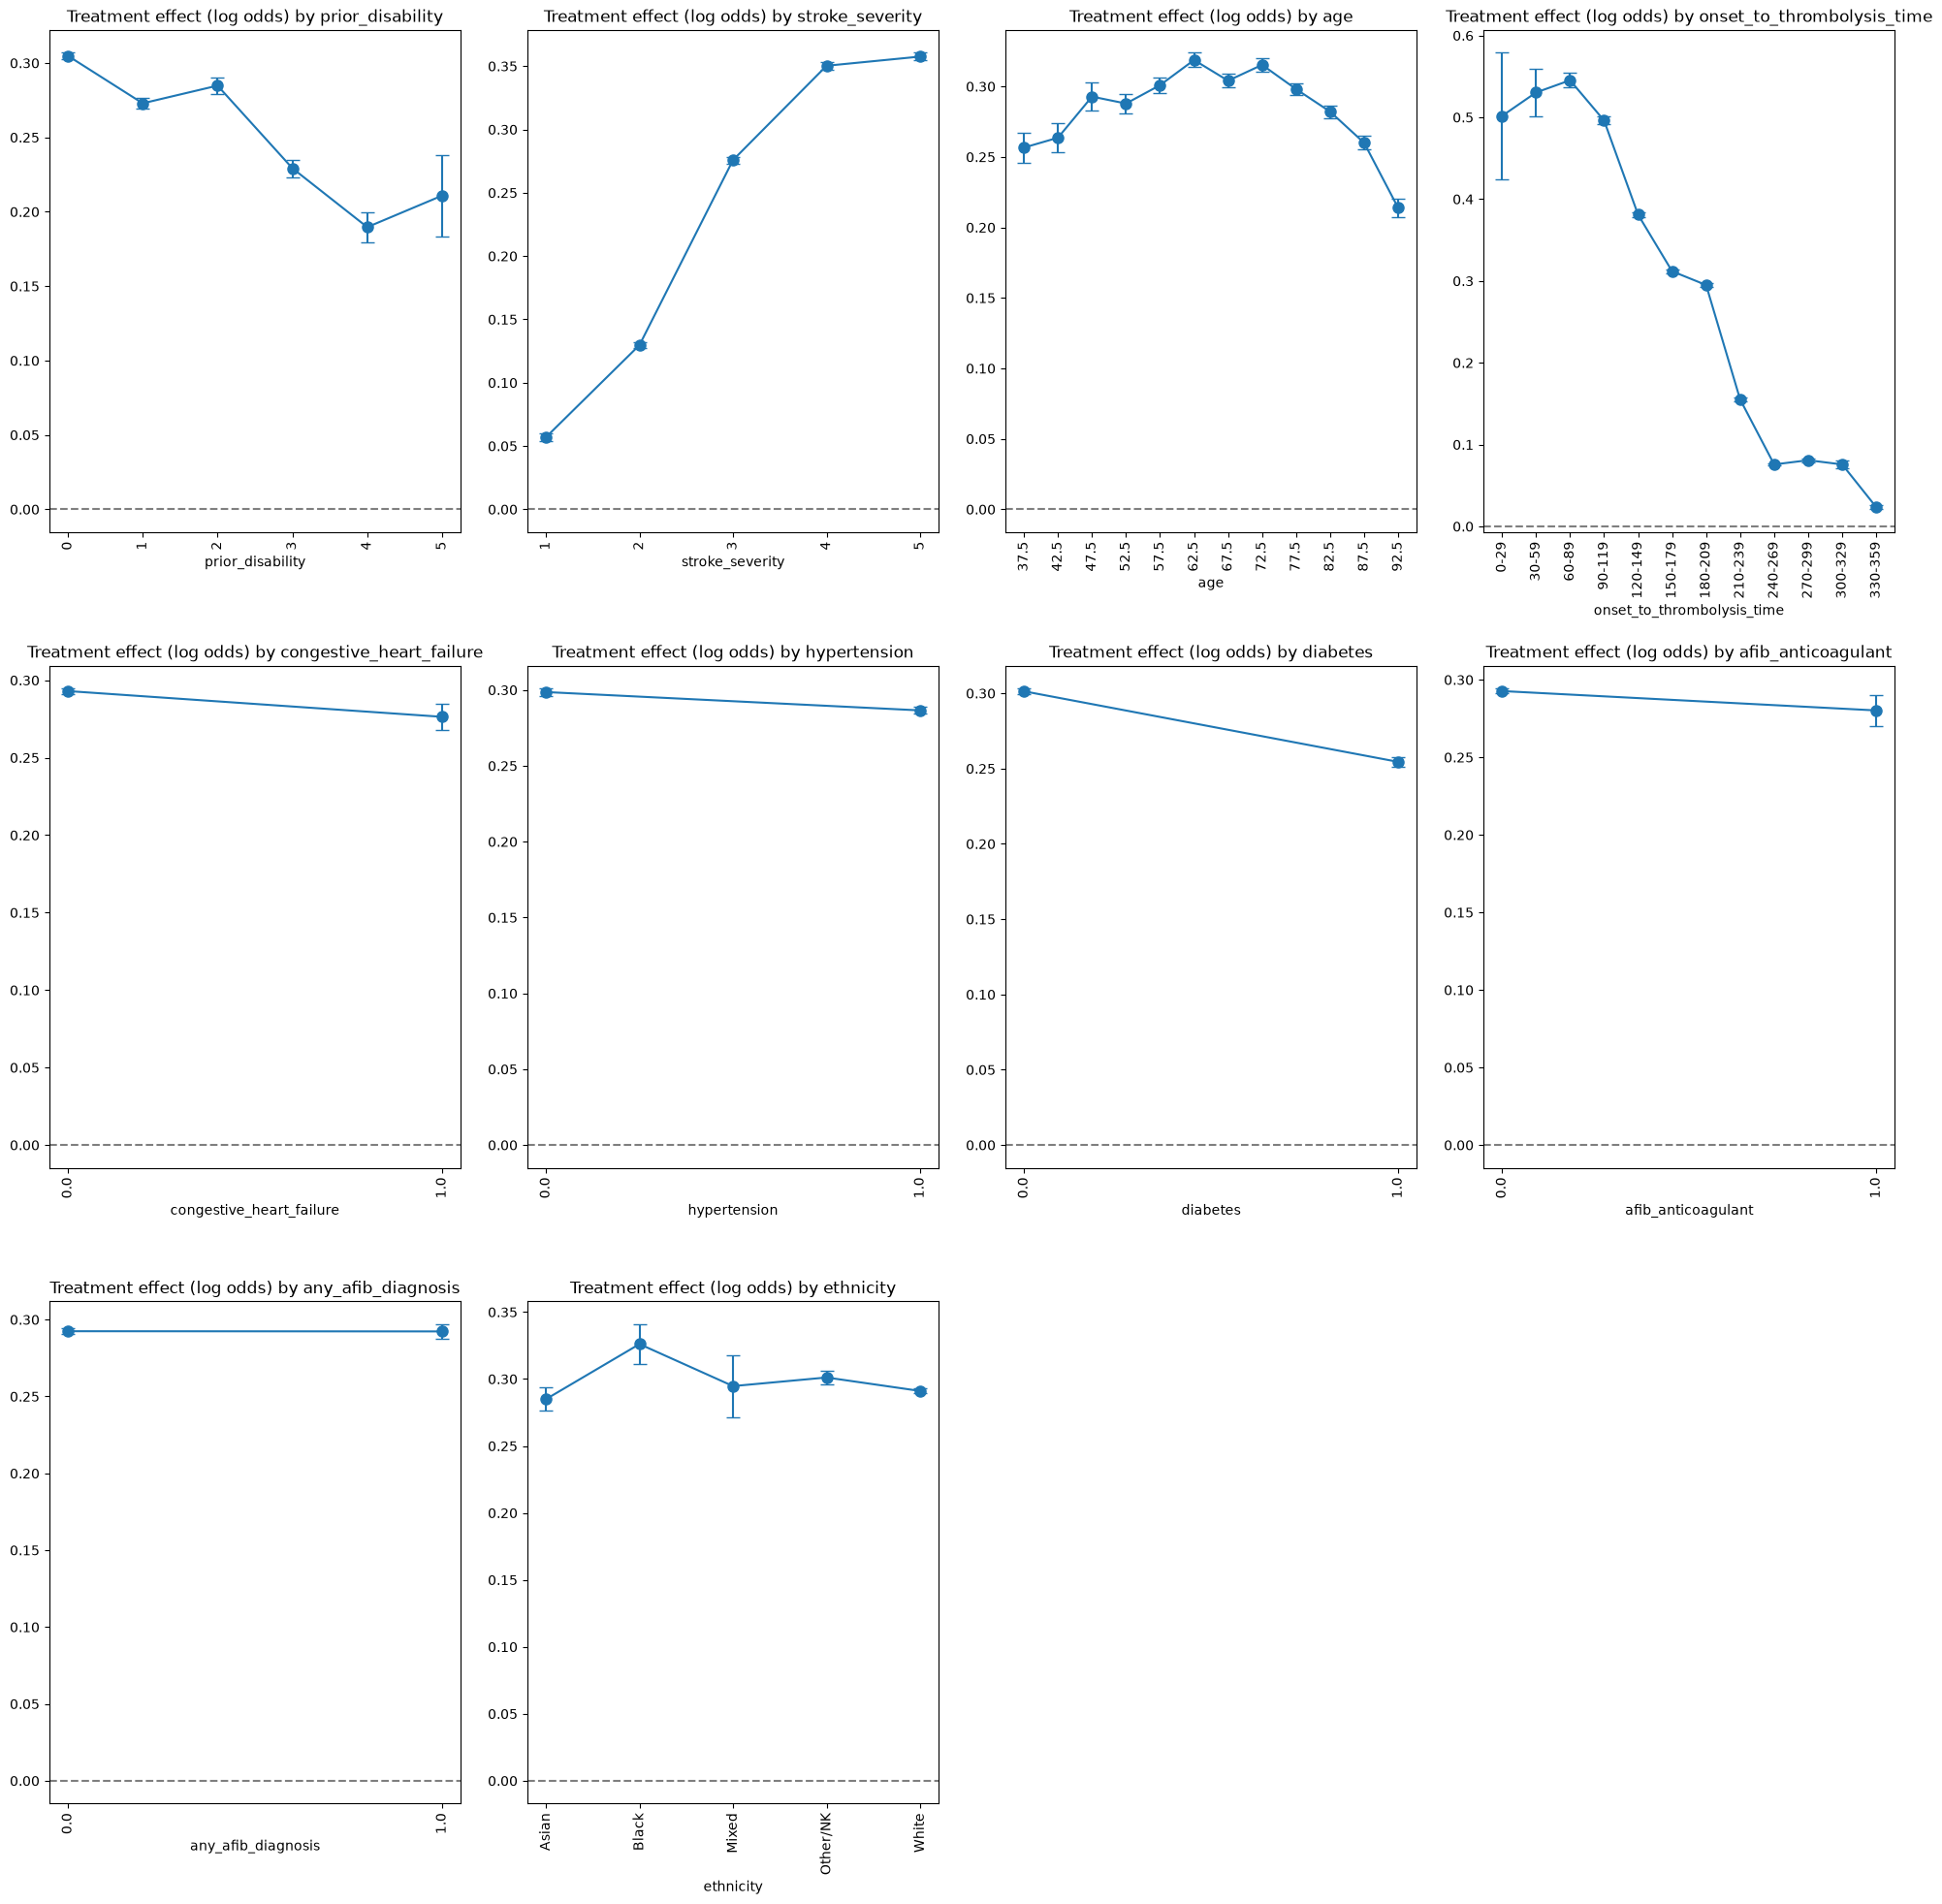

In [13]:
EFFECT_FEATURES = [
    "prior_disability",
    "stroke_severity",
    "age",
    TIME_THROMBOLYSIS,
    "congestive_heart_failure",
    "hypertension",
    "diabetes",
    "afib_anticoagulant",
    "any_afib_diagnosis",
    "ethnicity",
]


def time_bin_labels(starts, width=30):
    """Labels such as '120-149' for binned times."""
    return [f"{start}-{start + width - 1}" for start in starts]


fig, axes = plt.subplots(3, 4, figsize=(20, 20))

for ax, feature in zip(axes.flat, EFFECT_FEATURES):
    plot_df = cf[[feature, "log_odds_diff"]].dropna()
    if feature == TIME_THROMBOLYSIS:
        plot_df[feature] = (plot_df[feature] // 30 * 30).astype(int)

    grouped = plot_df.groupby(feature, observed=True)["log_odds_diff"].agg(["mean", "sem"])
    x_values = np.arange(len(grouped))

    ax.errorbar(x_values, grouped["mean"], yerr=grouped["sem"], fmt="o-", markersize=8, capsize=5)
    ax.axhline(0, color="black", linestyle="--", alpha=0.5)
    ax.set_title(f"Treatment effect (log odds) by {feature}")
    ax.set_xlabel(feature)
    ax.set_xticks(x_values)
    ax.tick_params(axis="x", rotation=90)

    if feature == TIME_THROMBOLYSIS:
        ax.set_xticklabels(time_bin_labels(grouped.index))
    elif feature == "stroke_severity":
        ax.set_xticklabels([f"{v:.0f}" for v in grouped.index])
    else:
        ax.set_xticklabels([str(v) for v in grouped.index])

for ax in axes.flat[len(EFFECT_FEATURES):]:
    ax.axis("off")

plt.tight_layout(pad=2)
plt.savefig(output_path("treatment_effects.png"), dpi=300, bbox_inches="tight")
plt.show()

**Comment.** Estimated benefit:
* is close to zero at NIHSS 1 (log odds ratio about 0.01) and rises steeply with severity: about 0.11 at NIHSS 2, 0.25 at NIHSS 3 and 0.32-0.33 at NIHSS 4-5;
* is greatest when thrombolysis is given within about 2 hours (about 0.45), and falls to about 0.1 by 4 hours and near zero after 5 hours;
* is smaller in patients over about 80, in those with more pre-stroke disability, and in those with diabetes.

Other comorbidities show little difference.

## Benefit by onset-to-thrombolysis time

An ordinary least squares (OLS) regression of individual predicted benefit (log odds ratio) on onset-to-thrombolysis time gives:

* **Benefit at time zero** (the intercept), with 95% CI.
* **Time at which predicted benefit reaches zero**: x = -intercept / slope. Its 95% CI uses the delta method:
  Var(x) = Var(a)/b^2 + a^2 Var(b)/b^4 - 2a Cov(a, b)/b^3, where a is the intercept and b the slope.
  When the zero point lies beyond the observed times this is an extrapolation.

Note: the 'observations' are model predictions, not independent outcomes, so OLS standard errors and p-values are too small. Treat the regression as a description of how the S-learner's estimated benefit changes with time.

In [14]:
def fit_time_regression(df, time_col=TIME_THROMBOLYSIS, benefit_col="log_odds_diff"):
    """OLS of benefit on time; return the fit and a dict of key quantities with 95% CIs."""
    ols = sm.OLS(df[benefit_col], sm.add_constant(df[[time_col]])).fit()
    intercept, slope = ols.params["const"], ols.params[time_col]
    cov = ols.cov_params()
    intercept_ci = ols.conf_int().loc["const"]

    result = {
        "n": int(ols.nobs),
        "intercept": intercept,
        "intercept CI lower": intercept_ci.iloc[0],
        "intercept CI upper": intercept_ci.iloc[1],
        "slope per hour": slope * 60,
        "R-squared": ols.rsquared,
        "time at zero benefit": np.nan,
        "time at zero CI lower": np.nan,
        "time at zero CI upper": np.nan,
    }
    if not np.isclose(slope, 0):
        x_at_zero = -intercept / slope
        variance = (
            cov.loc["const", "const"] / slope**2
            + intercept**2 * cov.loc[time_col, time_col] / slope**4
            - 2 * intercept * cov.loc["const", time_col] / slope**3
        )
        half_width = 1.96 * np.sqrt(max(variance, 0))
        result.update({
            "time at zero benefit": x_at_zero,
            "time at zero CI lower": x_at_zero - half_width,
            "time at zero CI upper": x_at_zero + half_width,
        })
    return ols, result


ols_time, time_result = fit_time_regression(cf)
print(ols_time.summary())
print(f"\nPredicted benefit at time zero (intercept): {time_result['intercept']:.4f}, "
      f"95% CI: [{time_result['intercept CI lower']:.4f}, {time_result['intercept CI upper']:.4f}]")
print(f"Time at which predicted benefit is zero: {time_result['time at zero benefit']:.0f} mins, "
      f"95% CI: [{time_result['time at zero CI lower']:.0f}, {time_result['time at zero CI upper']:.0f}] mins")

                            OLS Regression Results                            
Dep. Variable:          log_odds_diff   R-squared:                       0.504
Model:                            OLS   Adj. R-squared:                  0.504
Method:                 Least Squares   F-statistic:                 1.360e+04
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:58:10   Log-Likelihood:                 7967.2
No. Observations:               13378   AIC:                        -1.593e+04
Df Residuals:                   13376   BIC:                        -1.592e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

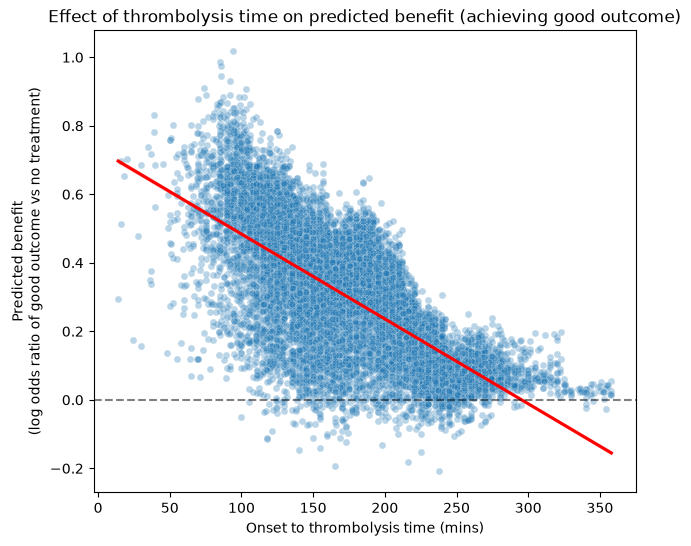

In [15]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=cf, x=TIME_THROMBOLYSIS, y="log_odds_diff", s=25, alpha=0.3, ax=ax)
sns.regplot(data=cf, x=TIME_THROMBOLYSIS, y="log_odds_diff", scatter=False, ci=95,
            line_kws={"color": "red"}, ax=ax)
ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_title("Effect of thrombolysis time on predicted benefit (achieving good outcome)")
ax.set_xlabel("Onset to thrombolysis time (mins)")
ax.set_ylabel(f"Predicted benefit\n(log odds ratio of good outcome vs no treatment)")
fig.savefig(output_path("thrombolysis_time_effect.png"), dpi=300, bbox_inches="tight")
plt.show()

**Comment.** Predicted benefit falls by about 0.14 (log odds ratio) per hour. The extrapolated benefit at time zero is 0.69 (OR about 2.0), and the fitted line reaches zero at about 289 minutes (95% CI 287 to 291). Time explains about half (R-squared 0.48) of the variation in individual estimates.

## Benefit by onset-to-thrombolysis time, for each NIHSS

The same regression fitted separately for each stroke severity (NIHSS 1 to 5). Lines are drawn over the observed time range for each NIHSS, with 95% confidence bands for the fitted line.

In [16]:
severity_fits, severity_rows = {}, []
for severity in range(1, 6):
    ols, result = fit_time_regression(cf[cf["stroke_severity"] == severity])
    severity_fits[severity] = ols
    severity_rows.append({"stroke_severity": severity, **result})

severity_results = pd.DataFrame(severity_rows).set_index("stroke_severity")
severity_results.to_csv(output_path("time_effect_by_nihss.csv"))
severity_results.round(3)

,n,intercept,intercept CI lower,intercept CI upper,slope per hour,R-squared,time at zero benefit,time at zero CI lower,time at zero CI upper
stroke_severity,,,,,,,,,
1,722,0.194,0.175,0.213,-0.044,0.234,262.698,250.154,275.242
2,1747,0.308,0.296,0.320,-0.059,0.355,313.560,304.504,322.617
3,2784,0.644,0.633,0.655,-0.124,0.636,311.273,307.239,315.307
4,3951,0.852,0.842,0.862,-0.171,0.723,299.600,296.998,302.202
5,4174,0.898,0.887,0.908,-0.186,0.735,290.181,287.860,292.503


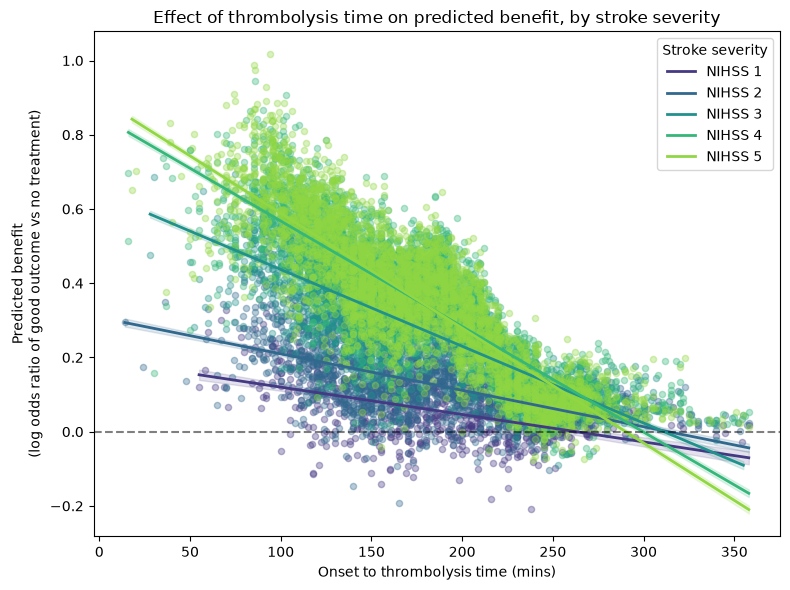

In [17]:
colors = sns.color_palette("viridis", n_colors=5)
fig, ax = plt.subplots(figsize=(8, 6))

for (severity, ols), color in zip(severity_fits.items(), colors):
    group = cf[cf["stroke_severity"] == severity]
    x_grid = np.linspace(group[TIME_THROMBOLYSIS].min(), group[TIME_THROMBOLYSIS].max(), 200)
    prediction = ols.get_prediction(pd.DataFrame({"const": 1.0, TIME_THROMBOLYSIS: x_grid})).summary_frame()

    ax.scatter(group[TIME_THROMBOLYSIS], group["log_odds_diff"], color=color, alpha=0.35, s=20)
    ax.plot(x_grid, prediction["mean"], color=color, linewidth=2, label=f"NIHSS {severity}")
    ax.fill_between(x_grid, prediction["mean_ci_lower"], prediction["mean_ci_upper"], color=color, alpha=0.15)

ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_title("Effect of thrombolysis time on predicted benefit, by stroke severity")
ax.set_xlabel("Onset to thrombolysis time (mins)")
ax.set_ylabel("Predicted benefit\n(log odds ratio of good outcome vs no treatment)")
ax.legend(title="Stroke severity")
fig.tight_layout()
fig.savefig(output_path("thrombolysis_time_effect_by_nihss.png"), dpi=300, bbox_inches="tight")
plt.show()

**Comment.** Benefit at time zero rises with NIHSS: 0.13 (NIHSS 1), 0.28 (2), 0.60 (3), 0.78 (4), 0.87 (5). The decline with time is steeper at higher NIHSS. At **NIHSS 1** the estimated benefit is small even for early treatment and reaches zero by about 3.5 hours (207 minutes, 95% CI 197 to 216). For NIHSS 2-5 the zero point is at about 285-310 minutes.

# Meta-model of benefit

## Method

An XGBoost regression model is fitted to the individual estimated benefit (log odds ratio) of thrombolysed patients, using the same features as the S-learner (including onset-to-thrombolysis time and stroke team). SHAP values for this meta-model show which characteristics are associated with larger or smaller estimated benefit (treatment-effect heterogeneity), each adjusted for the others.

* In-sample R-squared is optimistic (the model is evaluated on its own training data), so a 5-fold out-of-fold R-squared is also reported.
* The meta-model describes the S-learner's estimates. It cannot find heterogeneity the S-learner did not estimate, and inherits any bias in it.

In [18]:
meta_X = cf[X_FIELDS]
meta_y = cf["log_odds_diff"]


def make_meta_model():
    return XGBRegressor(enable_categorical=True, verbosity=0, random_state=RANDOM_STATE, eval_metric="rmse")


meta_model = make_meta_model().fit(meta_X, meta_y)
cf["predicted_log_odds_diff"] = meta_model.predict(meta_X)
cf["oof_predicted_log_odds_diff"] = cross_val_predict(
    make_meta_model(), meta_X, meta_y,
    cv=KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE),
)

r2_in_sample = r2_score(meta_y, cf["predicted_log_odds_diff"])
r2_out_of_fold = r2_score(meta_y, cf["oof_predicted_log_odds_diff"])
print(f"Meta-model R-squared: in-sample {r2_in_sample:.4f}, out-of-fold {r2_out_of_fold:.4f}")

Meta-model R-squared: in-sample 0.9739, out-of-fold 0.8891


**Comment.** The meta-model reproduces the S-learner's estimated benefit well out-of-fold (R-squared 0.89, in-sample 0.97). With the tuned S-learner, the variation in estimated benefit is systematic, i.e. explained by patient features, rather than noise (the original specification gave 0.37).

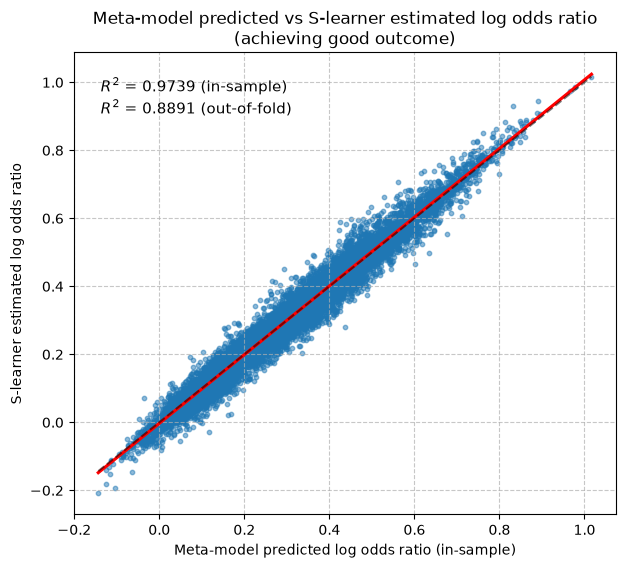

In [19]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.regplot(x="predicted_log_odds_diff", y="log_odds_diff", data=cf, ci=95, ax=ax,
            scatter_kws={"s": 10, "alpha": 0.5}, line_kws={"color": "red"})
limits = [cf["predicted_log_odds_diff"].min(), cf["predicted_log_odds_diff"].max()]
ax.plot(limits, limits, color="black", linestyle="--", alpha=0.5)  # y = x
ax.set_title(f"Meta-model predicted vs S-learner estimated log odds ratio\n(achieving good outcome)")
ax.set_xlabel("Meta-model predicted log odds ratio (in-sample)")
ax.set_ylabel("S-learner estimated log odds ratio")
ax.grid(linestyle="--", alpha=0.7)
ax.text(0.05, 0.95, f"$R^2$ = {r2_in_sample:.4f} (in-sample)\n$R^2$ = {r2_out_of_fold:.4f} (out-of-fold)",
        transform=ax.transAxes, fontsize=11, verticalalignment="top")
plt.show()

## SHAP values for the meta-model

Positive SHAP values mean the feature value is associated with *greater* estimated benefit from thrombolysis. The SHAP base value is the average predicted benefit.

SHAP base value (mean predicted log odds ratio): 0.292


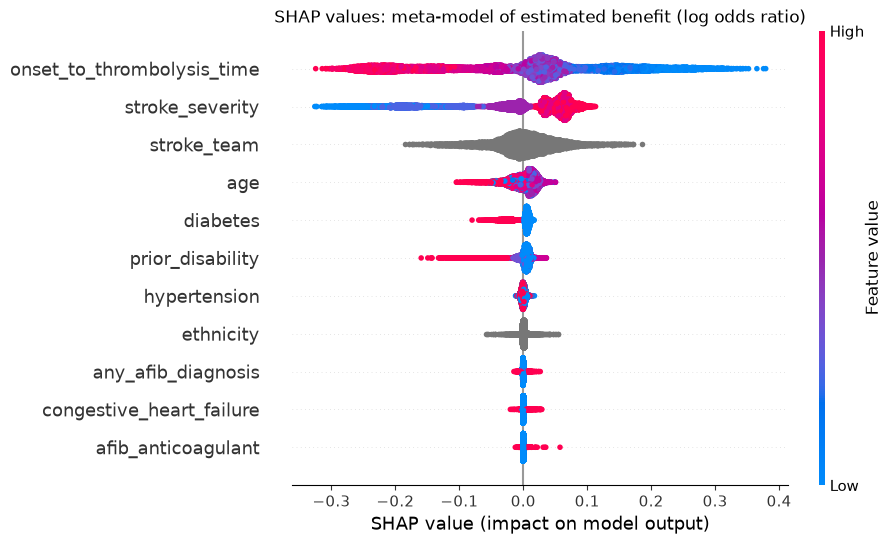

In [20]:
meta_explainer = shap.Explainer(meta_model)
meta_shap_values = meta_explainer(meta_X)
base_value = float(np.ravel(meta_explainer.expected_value)[0])
print(f"SHAP base value (mean predicted log odds ratio): {base_value:.3f}")

shap.plots.beeswarm(meta_shap_values, max_display=99, show=False)
plt.title("SHAP values: meta-model of estimated benefit (log odds ratio)")
plt.savefig(output_path("treatment_effect_shap_beeswarm.png"), dpi=300, bbox_inches="tight")
plt.show()

**Comment.** **Time to thrombolysis** and **NIHSS** are the main drivers of variation in estimated benefit, followed by stroke team and age. Shorter times and higher NIHSS (3-5) increase benefit; NIHSS 1-2, older age, diabetes and higher pre-stroke disability reduce it. The stroke-team contribution (smaller than with the original specification) may partly reflect which mild strokes a team chooses to treat, i.e. selection the model cannot see, rather than true differences in effectiveness.

### SHAP values by feature value

One panel per feature (stroke team is in the model but not plotted), all on the same y-axis scale; box whiskers show the full range; thrombolysis time is grouped into 30-minute bins.

* Black dashed line: SHAP = 0 (no change from the average benefit).
* Red dotted line: SHAP = -base value. A feature value whose SHAP falls below this line would, on its own, remove all of the average benefit (if other features did not compensate).

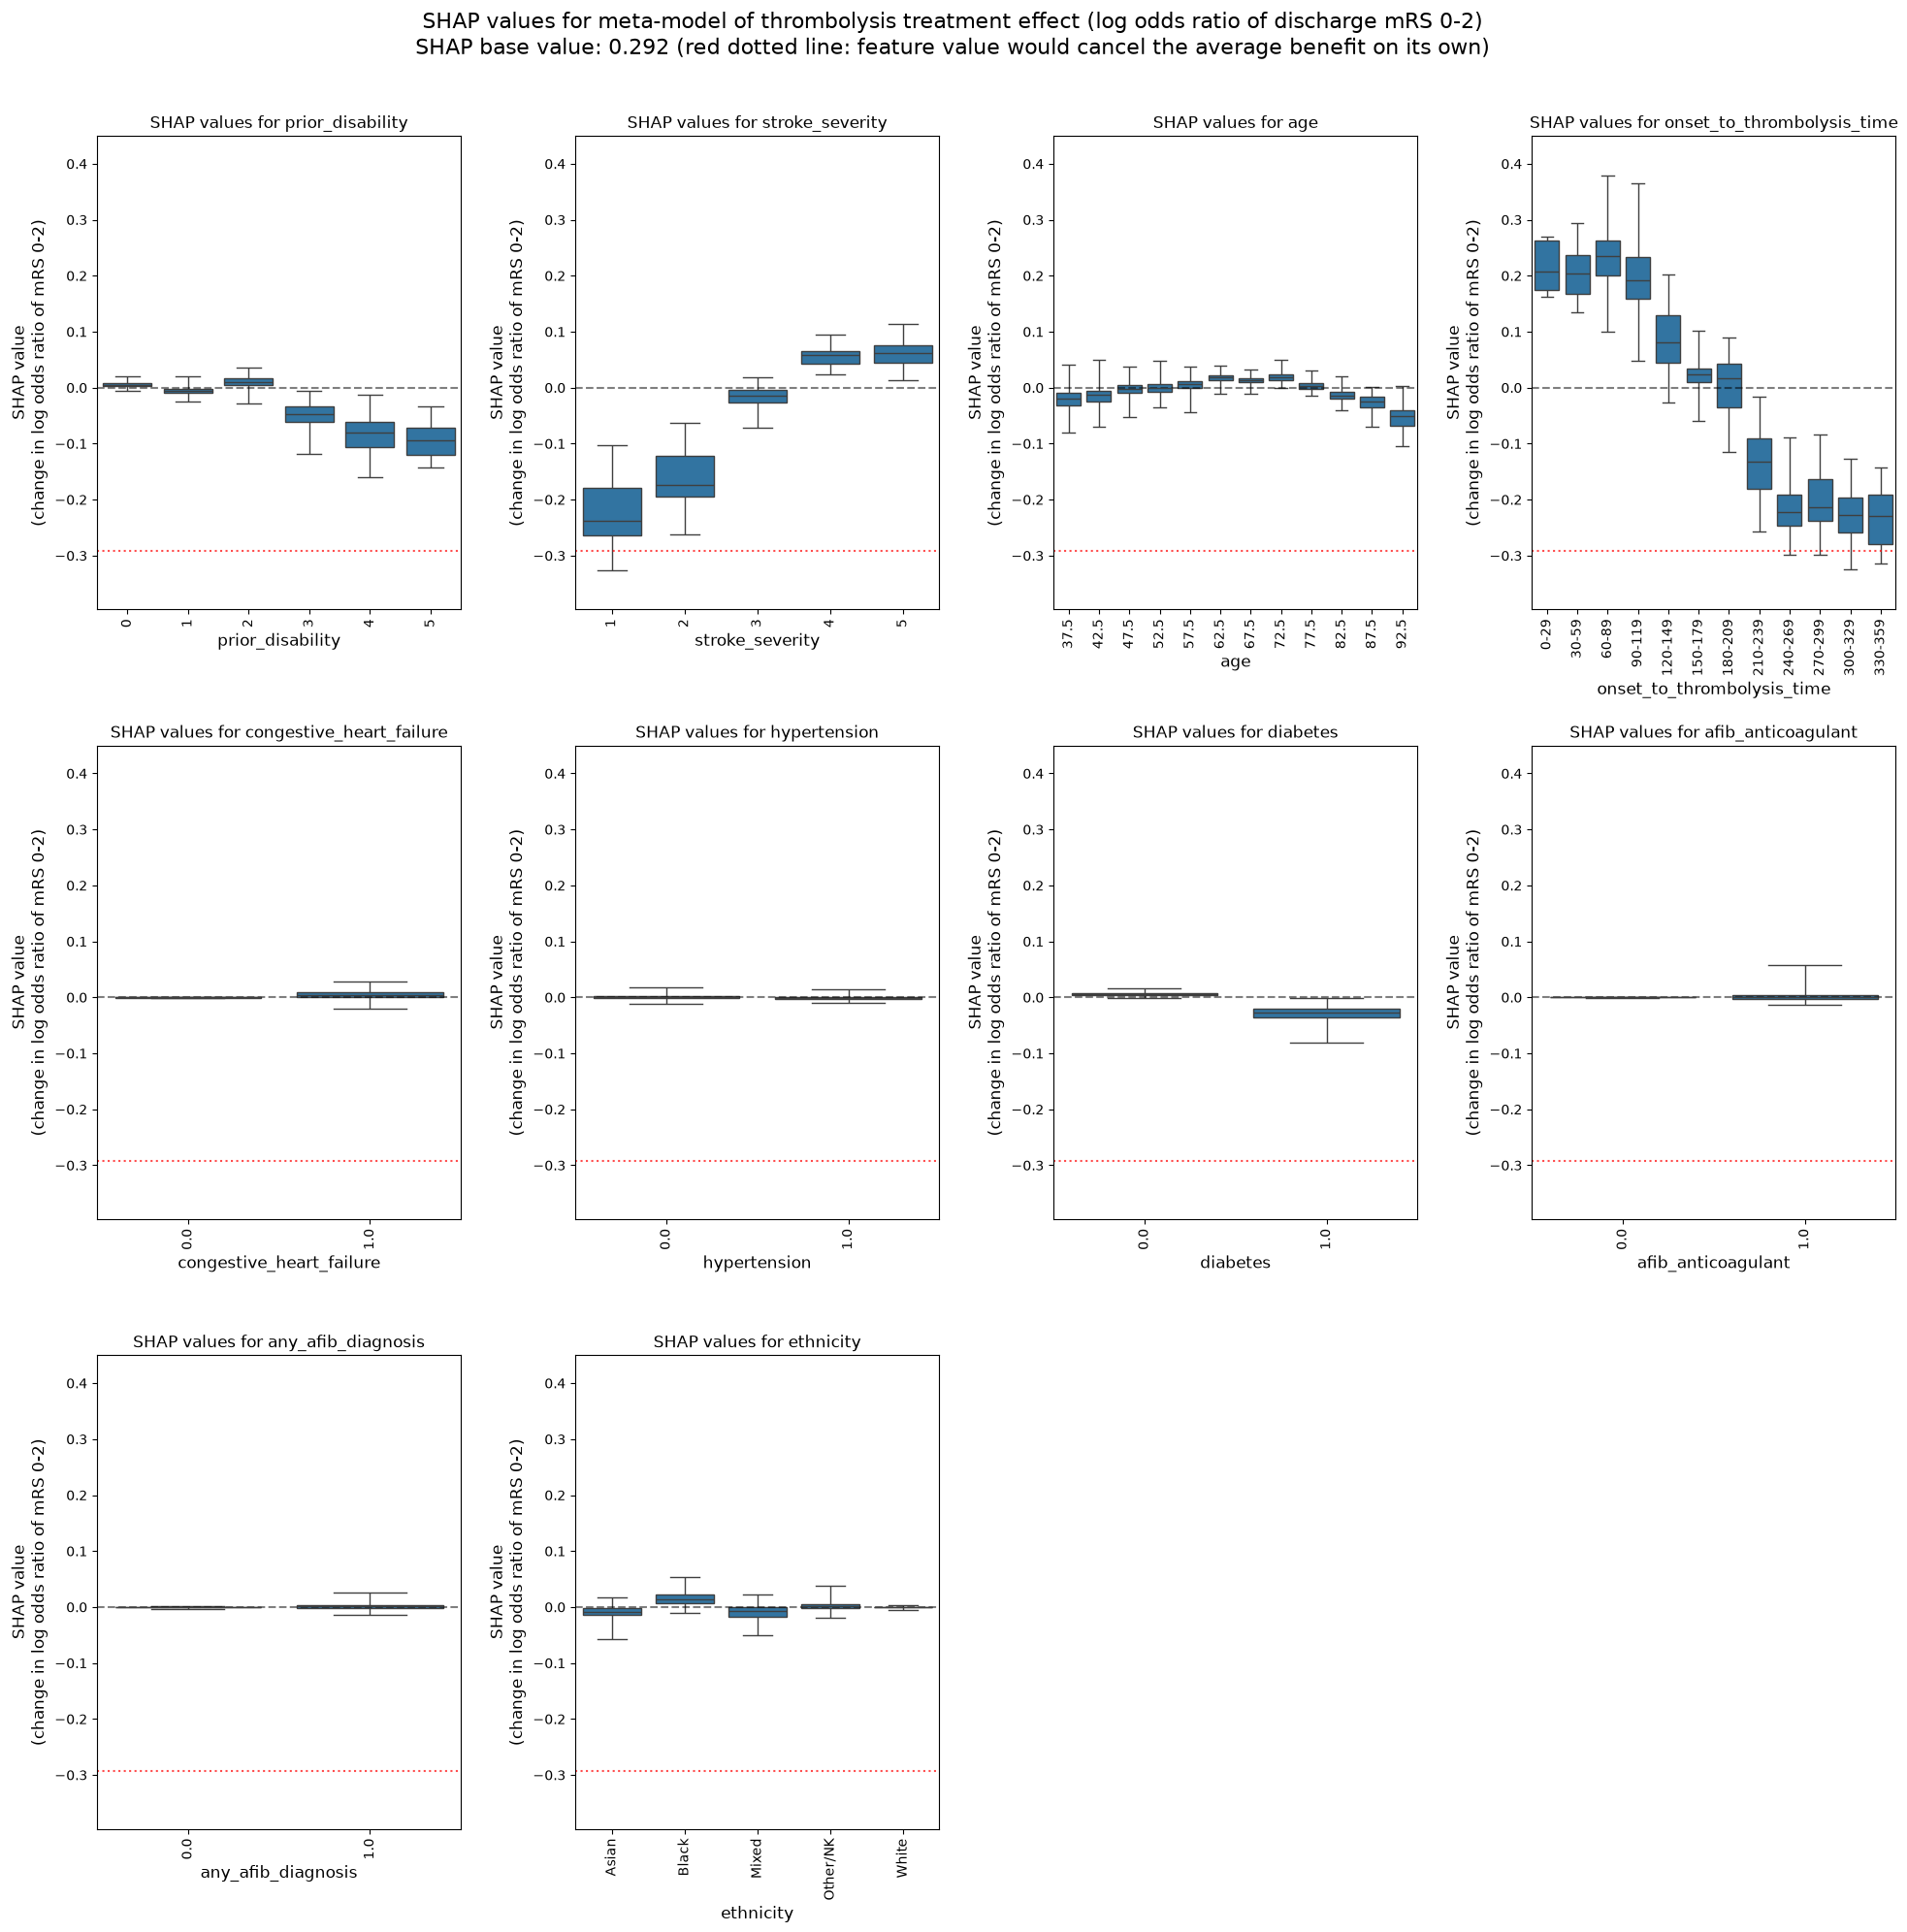

In [21]:
meta_shap_df = pd.DataFrame(meta_shap_values.values, columns=meta_X.columns, index=meta_X.index)

shap_min, shap_max = meta_shap_df.min().min(), meta_shap_df.max().max()
padding = 0.1 * (shap_max - shap_min)
y_limits = (min(shap_min, -base_value) - padding, shap_max + padding)

fig, axes = plt.subplots(3, 4, figsize=(20, 20))

for ax, feature in zip(axes.flat, EFFECT_FEATURES):
    plot_df = pd.DataFrame({
        "feature_value": meta_X[feature].to_numpy(),
        "shap_value": meta_shap_df[feature].to_numpy(),
    }).dropna()
    if feature == TIME_THROMBOLYSIS:
        plot_df["feature_value"] = (pd.to_numeric(plot_df["feature_value"]) // 30 * 30).astype(int)
    order = sorted(plot_df["feature_value"].unique())

    sns.boxplot(data=plot_df, x="feature_value", y="shap_value", order=order, ax=ax, whis=(0, 100))
    ax.axhline(0, color="black", linestyle="--", alpha=0.5)
    ax.axhline(-base_value, color="red", linestyle="dotted", alpha=0.7)
    ax.set_ylim(y_limits)
    ax.set_title(f"SHAP values for {feature}")
    ax.set_xlabel(feature, fontsize=12)
    ax.set_ylabel(f"SHAP value\n(change in log odds ratio of mRS 0-{MRS_TARGET})", fontsize=12)
    ax.tick_params(axis="x", rotation=90, labelsize=10)

    if feature == TIME_THROMBOLYSIS:
        ax.set_xticklabels(time_bin_labels(order))
    elif feature == "stroke_severity":
        ax.set_xticklabels([f"{float(v):.0f}" for v in order])

for ax in axes.flat[len(EFFECT_FEATURES):]:
    ax.axis("off")

fig.suptitle(
    f"SHAP values for meta-model of thrombolysis treatment effect (log odds ratio of discharge mRS 0-{MRS_TARGET})\n"
    f"SHAP base value: {base_value:.3f} (red dotted line: feature value would cancel the average benefit on its own)",
    fontsize=16, y=1.00,
)
plt.tight_layout(pad=2)
plt.savefig(output_path("shap_box_plots_good_outcome.png"), dpi=300, bbox_inches="tight")
plt.show()

# Sensitivity analysis

The S-learner estimates rest on assumptions and analytic choices. This section tests how far the main results (average benefit, benefit by time and by NIHSS) depend on them.

| Concern | Analysis |
|---|---|
| **Positivity / overlap**: are there comparable untreated patients for thrombolysed patients? | S1: propensity model for thrombolysis; check its distribution; re-estimate after trimming extreme propensities (in S2). |
| **Analytic choices**: class weighting, fold allocation, outcome definition, covariate set, population, model flexibility, model class | S2: re-run the pipeline under alternative specifications and compare. |
| **Unmeasured confounding**, e.g. whether the deficit is disabling (not captured by NIHSS), imaging findings, antiplatelet strategy | S3: E-values, overall and by time to thrombolysis. |
| **Uncertainty not captured by current CIs**, and other designs | S4: further options (not run here). |

Runtime: S2 fits 5 models for each of 13 scenarios, so it takes a few minutes.

## S1. Overlap (positivity)

An XGBoost classifier predicts the probability of receiving thrombolysis from the adjustment features, using out-of-fold predictions. Very different propensity distributions for thrombolysed and untreated patients, or many patients with propensities near 0 or 1, mean the S-learner must extrapolate when it predicts their counterfactual outcome.

Patients outside `PROPENSITY_TRIM` are counted below and are excluded in the trimmed scenario in S2.

Propensity model AUC (out-of-fold): 0.789


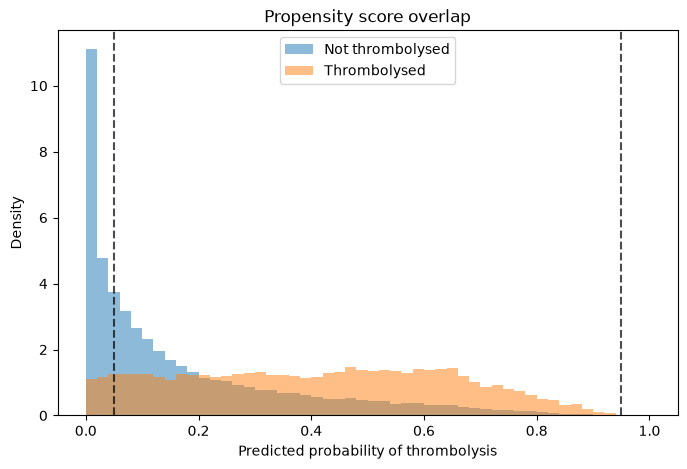

n outside trim range      proportion outside trim range  \
thrombolysis_given                    0    1                             0   
stroke_severity                                                              
1                                  5961  230                         0.580   
2                                  4820  212                         0.389   
3                                  2618  161                         0.260   
4                                  1559   86                         0.222   
5                                  1142   88                         0.218   

                           
thrombolysis_given      1  
stroke_severity            
1                   0.319  
2                   0.121  
3                   0.058  
4                   0.022  
5                   0.021

In [22]:
PROPENSITY_TRIM = (0.05, 0.95)
propensity_features = ADJUSTMENT_FEATURES + CATEGORICAL_FEATURES

data["propensity_thrombolysis"] = cross_val_predict(
    XGBClassifier(enable_categorical=True, verbosity=0, random_state=RANDOM_STATE, eval_metric="logloss"),
    data[propensity_features], data["thrombolysis_given"],
    cv=StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE),
    method="predict_proba",
)[:, 1]

print(f"Propensity model AUC (out-of-fold): "
      f"{roc_auc_score(data['thrombolysis_given'], data['propensity_thrombolysis']):.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
for label, value in [("Not thrombolysed", 0), ("Thrombolysed", 1)]:
    ax.hist(data.loc[data["thrombolysis_given"] == value, "propensity_thrombolysis"],
            bins=50, range=(0, 1), density=True, alpha=0.5, label=label)
for limit in PROPENSITY_TRIM:
    ax.axvline(limit, color="black", linestyle="--", alpha=0.7)
ax.set_xlabel("Predicted probability of thrombolysis")
ax.set_ylabel("Density")
ax.set_title("Propensity score overlap")
ax.legend()
fig.savefig(output_path("sensitivity_propensity_overlap.png"), dpi=300, bbox_inches="tight")
plt.show()

outside_trim = ~data["propensity_thrombolysis"].between(*PROPENSITY_TRIM)
(
    outside_trim.groupby([data["stroke_severity"], data["thrombolysis_given"]])
    .agg(["sum", "mean"])
    .rename(columns={"sum": "n outside trim range", "mean": "proportion outside trim range"})
    .unstack("thrombolysis_given")
    .round(3)
)

**Comment.** The propensity model has an AUC of 0.79. Overlap is poor at NIHSS 1: 58% of untreated and 32% of thrombolysed NIHSS-1 patients have a propensity outside 0.05-0.95 (almost all very low). At NIHSS 4-5 only about 2% of thrombolysed patients fall outside. Estimates at NIHSS 1 (and to a lesser degree NIHSS 2) rely most on model extrapolation.

## S2. Robustness to analytic choices

`run_thrombolysis_analysis` repeats the whole pipeline (outcome, 5-fold S-learner, counterfactual predictions) with one setting changed at a time. For each scenario it reports the mean benefit (log odds and probability), the regression of benefit on time (slope per hour; time at which benefit reaches zero), and the mean benefit by NIHSS.

| Scenario | What it tests |
|---|---|
| Base case | Reproduces the main analysis: tuned hyperparameters, no class weighting (check) |
| Original specification (default, weighted) | The specification used before tuning (default XGBoost settings, `scale_pos_weight` factor). Shows how much tuning changed the estimates. |
| Default XGBoost, no class weighting | Separates the effect of class weighting from the effect of tuning. |
| CV seed 1, CV seed 2 | Variability due to the random allocation of patients to folds |
| Outcome: mRS 0-2 only | Dropping the 'no worse than pre-stroke' rule |
| Outcome: mRS 0-1 or no worse | A stricter (excellent) outcome, commonly used in mild-stroke trials |
| Without stroke team | Team captures local practice and case mix; removing it shows how much estimates rely on within-team comparisons |
| Pre-stroke mRS 0-2 only | Restricts to previously independent patients, where the 'no worse than pre-stroke' rule rarely applies |
| Arrival within 3 hours | Earlier arrivals only |
| Propensity-trimmed (0.05-0.95) | Restricts to patients with overlap (see S1) |
| Regularised XGBoost | A fixed, heavily regularised specification (depth 3, 300 trees, learning rate 0.05, min child weight 10), unweighted: a further check on model flexibility. |

Hyperparameters are not re-tuned for each scenario: scenarios that use the base model use the tuned settings.
| Logistic regression S-learner | A parametric model: main effects plus a thrombolysis indicator and a linear time-to-thrombolysis term among treated patients. It tests model class, and gives a constant log odds ratio at a given time. |

In [23]:
def encode_thrombolysis(X):
    """For linear models: thrombolysis indicator, and time set to 0 when not given (so time only acts among treated)."""
    X = X.copy()
    given = X[TIME_THROMBOLYSIS] < NO_TREATMENT
    X["thrombolysis_indicator"] = given.astype(float)
    X[TIME_THROMBOLYSIS] = X[TIME_THROMBOLYSIS].where(given, 0.0)
    return X


def logistic_factory():
    """Logistic regression S-learner (main effects; numeric scaled, categorical one-hot encoded)."""
    def make_model(train_y):
        preprocess = ColumnTransformer([
            ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
             make_column_selector(dtype_exclude=["category", "object"])),
            ("categorical", make_pipeline(FunctionTransformer(lambda X: X.astype(str)),
                                          OneHotEncoder(handle_unknown="ignore")),
             make_column_selector(dtype_include=["category", "object"])),
        ])
        return make_pipeline(FunctionTransformer(encode_thrombolysis), preprocess,
                             LogisticRegression(max_iter=2000))
    return make_model


def run_thrombolysis_analysis(df, mrs_target=MRS_TARGET, include_no_worse=True,
                              features=None, model_factory=None, random_state=RANDOM_STATE):
    """Re-run the S-learner pipeline with alternative settings; return counterfactuals and performance."""
    features = features if features is not None else X_FIELDS
    model_factory = model_factory if model_factory is not None else xgb_factory(**best_params)
    outcome = good_outcome(df, mrs_target=mrs_target, include_no_worse=include_no_worse)
    scenario_folds = split_folds(df[features], outcome, random_state=random_state)
    scenario_models, scenario_performance = train_and_evaluate(scenario_folds, model_factory)
    return predict_thrombolysis_counterfactuals(scenario_models, scenario_folds), scenario_performance


SCENARIOS = {
    "Base case": {},
    "Original specification (default, weighted)": {"model_factory": xgb_factory(POS_WEIGHT_FACTOR)},
    "Default XGBoost, no class weighting": {"model_factory": xgb_factory(pos_weight_factor=None)},
    "CV seed 1": {"random_state": 1},
    "CV seed 2": {"random_state": 2},
    "Outcome: mRS 0-2 only": {"include_no_worse": False},
    "Outcome: mRS 0-1 or no worse": {"mrs_target": 1},
    "Without stroke team": {"features": [f for f in X_FIELDS if f != "stroke_team"]},
    "Pre-stroke mRS 0-2 only": {"population": lambda df: df[df["prior_disability"] <= 2]},
    "Arrival within 3 hours": {"population": lambda df: df[df["onset_to_arrival_time"] < 180]},
    "Propensity-trimmed (0.05-0.95)": {
        "population": lambda df: df[df["propensity_thrombolysis"].between(*PROPENSITY_TRIM)]
    },
    "Regularised XGBoost": {"model_factory": xgb_factory(
        None, max_depth=3, n_estimators=300, learning_rate=0.05, min_child_weight=10
    )},
    "Logistic regression S-learner": {"model_factory": logistic_factory()},
}

overall_rows, severity_rows = [], []

for scenario, settings in SCENARIOS.items():
    settings = dict(settings)
    population = settings.pop("population", None)
    scenario_data = population(data) if population is not None else data

    scenario_cf, scenario_performance = run_thrombolysis_analysis(scenario_data, **settings)

    log_odds = summarise_effect(scenario_cf["log_odds_diff"])
    prob = summarise_effect(scenario_cf["treatment_diff_prob"])
    _, time_fit = fit_time_regression(scenario_cf)
    overall_rows.append({
        "scenario": scenario,
        "patients": len(scenario_data),
        "thrombolysed": int(log_odds["n"]),
        "mean AUC": scenario_performance["AUC"].mean(),
        "observed positive rate": scenario_performance["actual_positive_rate"].mean(),
        "mean predicted probability": scenario_performance["mean_predicted_probability"].mean(),
        "log OR mean": log_odds["mean"],
        "log OR CI lower": log_odds["95% CI lower"],
        "log OR CI upper": log_odds["95% CI upper"],
        "prob diff mean": prob["mean"],
        "prob diff CI lower": prob["95% CI lower"],
        "prob diff CI upper": prob["95% CI upper"],
        "proportion negative effect": log_odds["proportion < 0"],
        "log OR slope per hour": time_fit["slope per hour"],
        "time at zero benefit": time_fit["time at zero benefit"],
        "time at zero CI lower": time_fit["time at zero CI lower"],
        "time at zero CI upper": time_fit["time at zero CI upper"],
    })

    by_severity = scenario_cf.groupby("stroke_severity")["log_odds_diff"].apply(summarise_effect).unstack()
    by_severity["scenario"] = scenario
    severity_rows.append(by_severity.reset_index())
    print(f"Completed: {scenario}")

sensitivity_overall = pd.DataFrame(overall_rows).set_index("scenario")
sensitivity_by_severity = pd.concat(severity_rows, ignore_index=True)
sensitivity_overall.to_csv(output_path("sensitivity_overall.csv"))
sensitivity_by_severity.to_csv(output_path("sensitivity_by_nihss.csv"), index=False)

Completed: Base case
Completed: Original specification (default, weighted)
Completed: Default XGBoost, no class weighting
Completed: CV seed 1
Completed: CV seed 2
Completed: Outcome: mRS 0-2 only
Completed: Outcome: mRS 0-1 or no worse
Completed: Without stroke team
Completed: Pre-stroke mRS 0-2 only
Completed: Arrival within 3 hours
Completed: Propensity-trimmed (0.05-0.95)
Completed: Regularised XGBoost
Completed: Logistic regression S-learner


### Model performance and overall benefit by scenario

In [24]:
sensitivity_overall[["patients", "thrombolysed", "mean AUC", "observed positive rate", "mean predicted probability"]].round(3)

,patients,thrombolysed,mean AUC,observed positive rate,mean predicted probability
scenario,,,,,
Base case,58387,13378,0.724,0.746,0.746
"Original specification (default, weighted)",58387,13378,0.691,0.746,0.599
"Default XGBoost, no class weighting",58387,13378,0.691,0.746,0.749
CV seed 1,58387,13378,0.724,0.746,0.746
CV seed 2,58387,13378,0.724,0.746,0.746
Outcome: mRS 0-2 only,58387,13378,0.816,0.666,0.666
Outcome: mRS 0-1 or no worse,58387,13378,0.712,0.562,0.562
Without stroke team,58387,13378,0.697,0.746,0.746
Pre-stroke mRS 0-2 only,50294,12522,0.729,0.755,0.755


In [25]:
sensitivity_overall[[
    "log OR mean", "log OR CI lower", "log OR CI upper",
    "prob diff mean", "prob diff CI lower", "prob diff CI upper",
    "proportion negative effect", "log OR slope per hour",
    "time at zero benefit", "time at zero CI lower", "time at zero CI upper",
]].round(3)

,log OR mean,log OR CI lower,log OR CI upper,prob diff mean,prob diff CI lower,prob diff CI upper,proportion negative effect,log OR slope per hour,time at zero benefit,time at zero CI lower,time at zero CI upper
scenario,,,,,,,,,,,
Base case,0.292,0.289,0.296,0.050,0.050,0.051,0.023,-0.149,295.363,293.179,297.547
"Original specification (default, weighted)",0.588,0.573,0.603,0.101,0.099,0.104,0.248,-0.305,293.028,286.523,299.533
"Default XGBoost, no class weighting",0.499,0.483,0.514,0.058,0.055,0.060,0.293,-0.259,292.634,284.675,300.593
CV seed 1,0.289,0.286,0.293,0.050,0.049,0.051,0.024,-0.147,295.336,293.088,297.584
CV seed 2,0.290,0.287,0.293,0.050,0.049,0.050,0.025,-0.151,292.735,290.624,294.845
Outcome: mRS 0-2 only,0.305,0.302,0.309,0.051,0.050,0.052,0.038,-0.143,305.738,302.954,308.522
Outcome: mRS 0-1 or no worse,0.285,0.282,0.287,0.063,0.062,0.063,0.006,-0.117,322.853,320.291,325.416
Without stroke team,0.287,0.284,0.291,0.050,0.050,0.051,0.066,-0.119,321.627,317.530,325.725
Pre-stroke mRS 0-2 only,0.291,0.287,0.294,0.050,0.050,0.051,0.035,-0.145,297.248,294.634,299.862


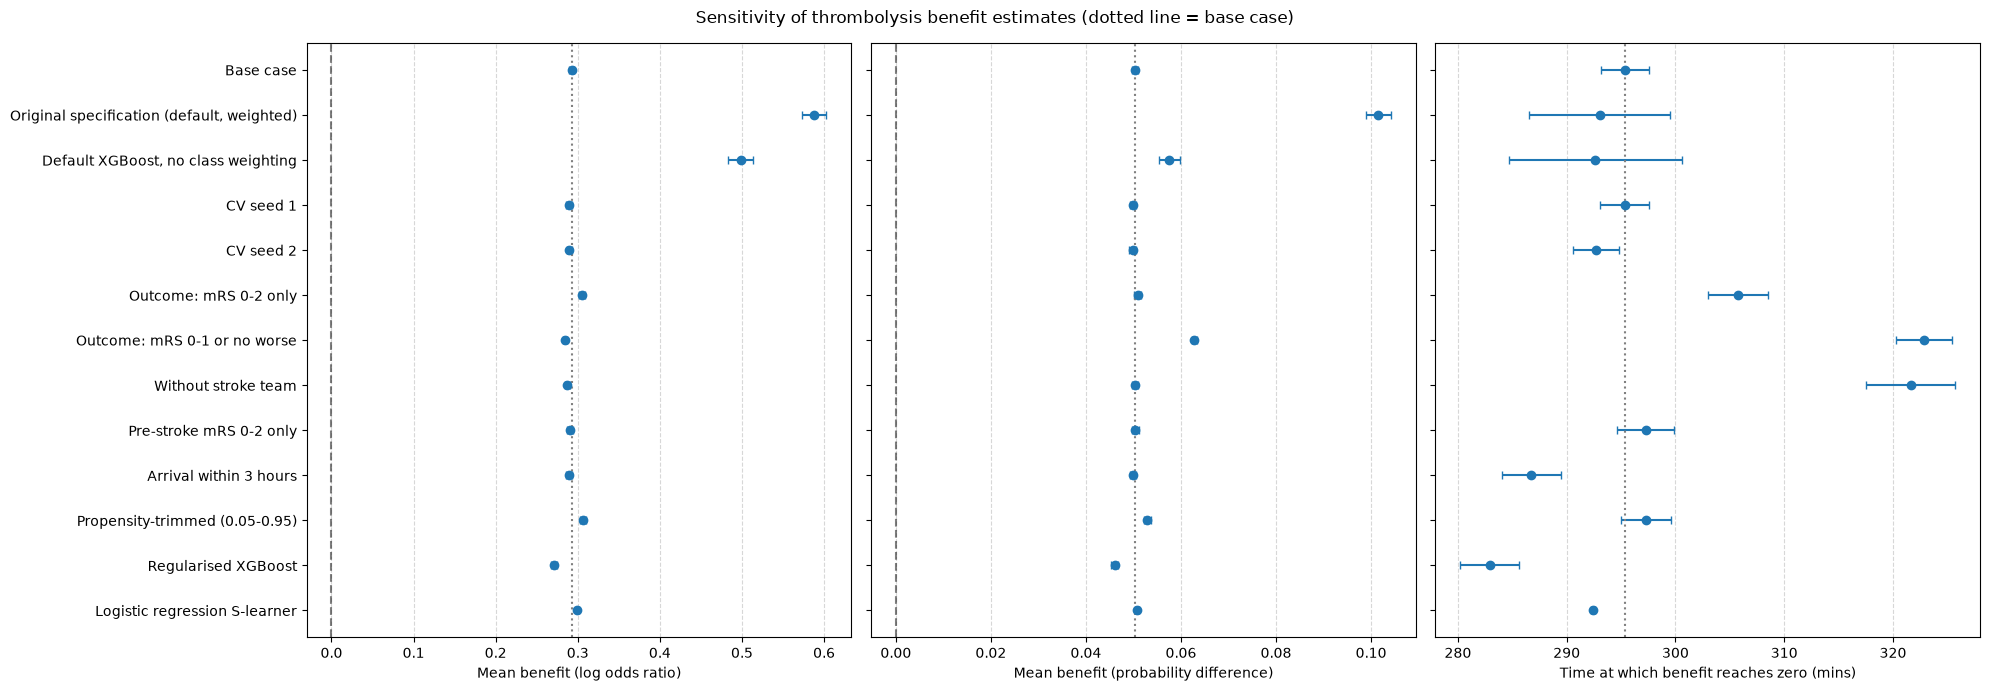

In [26]:
scenarios = list(SCENARIOS)
y_pos = np.arange(len(scenarios))[::-1]
res = sensitivity_overall.reindex(scenarios)

panels = [
    ("log OR", "Mean benefit (log odds ratio)"),
    ("prob diff", "Mean benefit (probability difference)"),
    ("time at zero", "Time at which benefit reaches zero (mins)"),
]
fig, axes = plt.subplots(1, 3, figsize=(20, 7), sharey=True)
for ax, (prefix, xlabel) in zip(axes, panels):
    mean_col = f"{prefix} mean" if prefix != "time at zero" else "time at zero benefit"
    ax.errorbar(
        res[mean_col], y_pos,
        xerr=[res[mean_col] - res[f"{prefix} CI lower"], res[f"{prefix} CI upper"] - res[mean_col]],
        fmt="o", capsize=3,
    )
    ax.axvline(res.loc["Base case", mean_col], color="grey", linestyle=":")
    if prefix != "time at zero":
        ax.axvline(0, color="black", linestyle="--", alpha=0.5)
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(scenarios)
fig.suptitle("Sensitivity of thrombolysis benefit estimates (dotted line = base case)")
fig.tight_layout()
fig.savefig(output_path("sensitivity_overall.png"), dpi=300, bbox_inches="tight")
plt.show()

### Benefit by NIHSS across scenarios

Mean log odds ratio (with 95% CI) by NIHSS for each scenario. This checks whether the pattern of benefit by severity, in particular any lack of benefit at NIHSS 1-2, is robust.

stroke_severity,1,2,3,4,5
scenario,,,,,
Base case,0.057,0.130,0.276,0.350,0.358
"Original specification (default, weighted)",0.212,0.335,0.594,0.667,0.681
"Default XGBoost, no class weighting",0.070,0.251,0.517,0.569,0.597
CV seed 1,0.045,0.120,0.274,0.349,0.356
CV seed 2,0.049,0.130,0.263,0.350,0.359
Outcome: mRS 0-2 only,0.030,0.108,0.275,0.363,0.401
Outcome: mRS 0-1 or no worse,0.114,0.169,0.273,0.340,0.318
Without stroke team,-0.023,0.100,0.278,0.365,0.352
Pre-stroke mRS 0-2 only,0.021,0.105,0.255,0.350,0.390


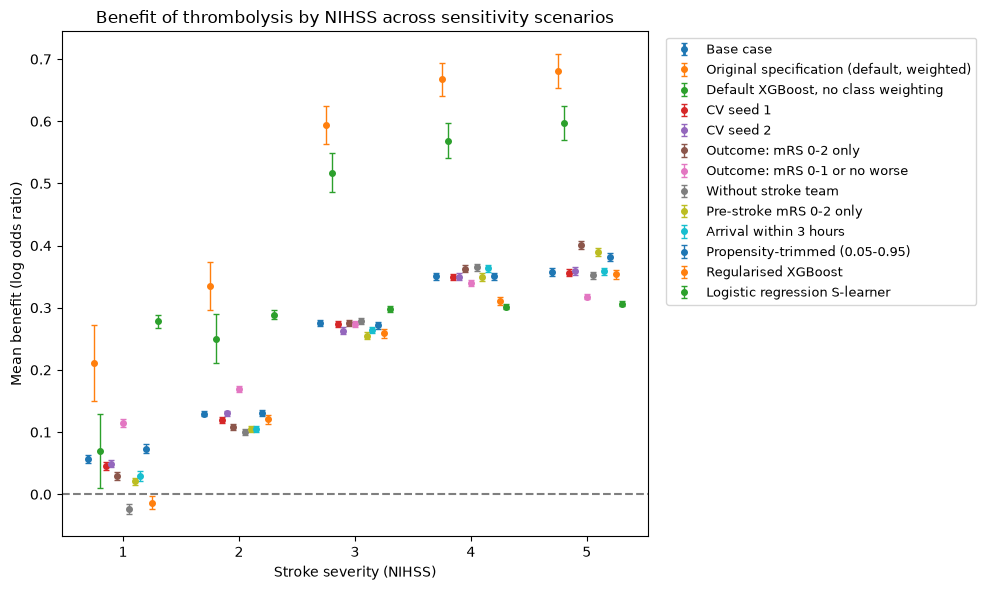

In [27]:
display(
    sensitivity_by_severity.pivot(index="scenario", columns="stroke_severity", values="mean")
    .reindex(scenarios).round(3)
)

fig, ax = plt.subplots(figsize=(10, 6))
offsets = np.linspace(-0.3, 0.3, len(scenarios))
for offset, scenario in zip(offsets, scenarios):
    s = sensitivity_by_severity[sensitivity_by_severity["scenario"] == scenario]
    ax.errorbar(
        s["stroke_severity"] + offset, s["mean"],
        yerr=[s["mean"] - s["95% CI lower"], s["95% CI upper"] - s["mean"]],
        fmt="o", capsize=2, markersize=4, label=scenario,
        linewidth=2 if scenario == "Base case" else 1,
    )
ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_xticks(range(1, 6))
ax.set_xlabel("Stroke severity (NIHSS)")
ax.set_ylabel("Mean benefit (log odds ratio)")
ax.set_title("Benefit of thrombolysis by NIHSS across sensitivity scenarios")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig(output_path("sensitivity_by_nihss.png"), dpi=300, bbox_inches="tight")
plt.show()

**Comment on S2.**

* **The tuned estimates are robust.** The mean log odds ratio stays within 0.25-0.30 (probability benefit 4.5-5.6 percentage points) across:
  * fold seeds;
  * outcome definitions;
  * removing stroke team;
  * previously independent patients only;
  * arrival within 3 hours;
  * propensity trimming;
  * the fixed regularised XGBoost;
  * the logistic regression S-learner.

  The time at which benefit reaches zero is about 275-315 minutes in every scenario.
* **Tuning, not class weighting, drives the change from the original analysis.** The original specification gives 0.59 (10 points), and default XGBoost without weighting 0.50 (6 points). Both have lower AUC (0.69) than the tuned model (0.72), and their individual estimates are far noisier (25-29% negative). Independent, more regularised and parametric models (regularised XGBoost, logistic regression) agree with the tuned model.
* **By NIHSS.** NIHSS 3-5: about 0.23-0.37 in all XGBoost scenarios. NIHSS 2: about 0.10-0.13. **NIHSS 1: about zero** in every tuned or regularised scenario (-0.04 to 0.05; 0.09 with the stricter mRS 0-1 outcome). The exception is the logistic model, which by construction gives the same effect at all NIHSS values and so cannot detect this.

## S3. Unmeasured confounding: E-values

The E-value (VanderWeele and Ding, 2017) is the minimum strength of association, on the risk-ratio scale, that an unmeasured confounder would need with *both* thrombolysis and outcome, beyond the measured covariates, to fully explain away the estimate. A second E-value is given for the confidence limit closest to the null (1 if the CI includes the null).

* Good outcome is common here (about 75%), so odds ratios are converted to approximate risk ratios with RR ~ sqrt(OR). Even this conversion can overstate the RR when the outcome is very common, so these E-values are, if anything, generous.
* The 'odds ratio' is exp(mean individual log odds ratio). This approximates, but is not the same as, a marginal odds ratio.
* E-values are given overall, by 60-minute bins of onset-to-thrombolysis time, and by NIHSS.
* Interpretation: the most plausible unmeasured confounder in mild stroke is whether the deficit is disabling. Clinicians tend to thrombolyse disabling deficits, which also carry worse prognosis. That would bias *against* benefit. In contrast, unrecorded factors such as frailty, or mimics among untreated patients, could bias in either direction.

In [28]:
def e_value_from_odds_ratio(odds_ratio):
    """E-value for an odds ratio, using RR ~ sqrt(OR) for a common outcome."""
    rr = np.sqrt(np.asarray(odds_ratio, dtype=float))
    rr = np.where(rr < 1, 1 / rr, rr)
    return rr + np.sqrt(rr * (rr - 1))


def e_value_table(groups):
    """E-values from mean log odds ratios for each group of patients."""
    table = groups["log_odds_diff"].apply(summarise_effect).unstack()
    out = np.exp(table[["mean", "95% CI lower", "95% CI upper"]])
    out.columns = ["OR", "OR 95% CI lower", "OR 95% CI upper"]
    out["E-value (estimate)"] = e_value_from_odds_ratio(out["OR"])
    ci_includes_null = (out["OR 95% CI lower"] <= 1) & (out["OR 95% CI upper"] >= 1)
    nearest = np.where(out["OR"] >= 1, out["OR 95% CI lower"], out["OR 95% CI upper"])
    out["E-value (CI limit)"] = np.where(ci_includes_null, 1.0, e_value_from_odds_ratio(nearest))
    out["n"] = table["n"].astype(int)
    return out


time_bins = pd.cut(cf[TIME_THROMBOLYSIS], bins=range(0, 361, 60), right=False,
                   labels=[f"{t}-{t + 59}" for t in range(0, 360, 60)])

e_values = pd.concat({
    "All thrombolysed": e_value_table(cf.groupby(np.zeros(len(cf), dtype=int))).rename(index={0: "all"}),
    "By time to thrombolysis (mins)": e_value_table(cf.groupby(time_bins, observed=True)),
    "By NIHSS": e_value_table(cf.groupby("stroke_severity")),
})
e_values.to_csv(output_path("sensitivity_e_values.csv"))
e_values.round(2)

OR  OR 95% CI lower  \
All thrombolysed               all      1.34             1.34   
By time to thrombolysis (mins) 0-59     1.69             1.61   
                               60-119   1.66             1.65   
                               120-179  1.41             1.41   
                               180-239  1.26             1.26   
                               240-299  1.08             1.08   
                               300-359  1.06             1.05   
By NIHSS                       1        1.06             1.05   
                               2        1.14             1.13   
                               3        1.32             1.31   
                               4        1.42             1.41   
                               5        1.43             1.42   

                                        OR 95% CI upper  E-value (estimate)  \
All thrombolysed               all                 1.34                1.58   
By time to thrombolysis (mins) 0-59                1.78                1.93   
                               60-119              1.67                1.90   
                               120-179             1.42                1.66   
                               180-239             1.27                1.50   
                               240-299             1.08                1.24   
                               300-359             1.07                1.21   
By NIHSS                       1                   1.07                1.20   
                               2                   1.14                1.33   
                               3                   1.32                1.56   
                               4                   1.43                1.67   
                               5                   1.44                1.68   

                                        E-value (CI limit)      n  
All thrombolysed               all                    1.58  13378  
By time to thrombolysis (mins) 0-59                   1.85     53  
                               60-119                 1.89   1917  
                               120-179                1.66   5216  
                               180-239                1.49   4086  
                               240-299                1.24   1963  
                               300-359                1.19    143  
By NIHSS                       1                      1.19    722  
                               2                      1.33   1747  
                               3                      1.55   2784  
                               4                      1.66   3951  
                               5                      1.67   4174

**Comment.** The overall E-value is 1.54. An unmeasured confounder associated with both thrombolysis and good outcome by a risk ratio of about 1.5 each, beyond measured covariates, could explain away the average effect. That is a moderate, not large, degree of confounding. E-values are lower where effects are smaller:
* about 1.1 at NIHSS 1;
* 1.3 at NIHSS 2;
* 1.2 for thrombolysis after 4 hours.

The highest E-values (about 1.8) are for treatment within 2 hours.

## S4. Further sensitivity analyses to consider (not run here)

* **Bootstrap the whole pipeline.** Current CIs (mean +/- 1.96 SD/sqrt(n) of individual predictions) ignore uncertainty in the fitted models and are too narrow. Resample patients, refit the cross-validated S-learner, and recompute the mean benefit, the benefit by NIHSS, and the time at zero benefit (e.g. 100-200 replicates).
* **Alternative meta-learners.** Compare with a T-learner (separate treated and untreated models), an X-learner, a doubly robust (DR) learner or a causal forest (e.g. `econml`). Doubly robust methods combine the outcome and propensity models and reduce reliance on either being correct.
* **Instrumental variable analysis.** Between-hospital variation in thrombolysis use for mild stroke is large. Hospital thrombolysis rate (in mild stroke) can be used as an instrument, which addresses unmeasured patient-level confounding (e.g. disabling vs non-disabling deficit), under its own assumptions.
* **Placebo / negative-control tests.** (a) Randomly reassign thrombolysis times among treated patients: any time gradient should disappear. (b) Use a negative-control outcome that thrombolysis cannot plausibly affect but that shares confounders.
* **Quantitative bias analysis** for a specified unmeasured confounder (e.g. prevalence of disabling deficit in treated vs untreated, and its effect on outcome), to complement E-values.
* **Comparison with trial evidence.** Trials of thrombolysis in minor, non-disabling stroke (e.g. PRISMS, ARAMIS) have not shown benefit over antiplatelet therapy. Restricting to patients most like trial populations (where data allow, e.g. NIHSS 0-5 without a disabling deficit) gives a direct check of whether the observational estimate is consistent.
* **Missing data, calibration, selection.** Compare native missing-value handling with multiple imputation; plot observed vs predicted outcome by decile for each fold; vary the arrival window and include perfusion-imaging patients.

# Commentary on results

## Main findings (tuned primary model)

1. **Average benefit.** Among patients with mild stroke (NIHSS 1-5) arriving within 4 hours, the S-learner estimates that thrombolysis increased the probability of a good discharge outcome by about **4.6 percentage points** (mean log odds ratio 0.27, OR 1.30). This is robust across fold allocation, outcome definitions, covariate sets, population restrictions and model classes (OR 1.28-1.35; 4.5-5.6 percentage points). It is less than half the estimate from the original, untuned and class-weighted specification (10 points, OR 1.8). That specification discriminated less well, was miscalibrated, and produced noisy individual estimates. The tuned estimate should be preferred.
2. **Time to treatment.** Benefit declines steadily with delay, by about 0.14 log odds ratio per hour: from an OR of about 1.6 within 2 hours to about 1.05 after 4 hours. The fitted benefit reaches zero at about 4.8 hours (275-315 minutes across all scenarios). Early treatment carries most of the benefit.
3. **Severity.** Benefit rises with NIHSS: OR about 1.11 at NIHSS 2, 1.29 at NIHSS 3, and about 1.4 at NIHSS 4-5. **At NIHSS 1 there is no meaningful estimated benefit** (OR about 1.01), consistently across scenarios. NIHSS 1 also has the poorest overlap between treated and untreated patients.
4. **Other heterogeneity.** Benefit is smaller in older patients (above about 80), in those with diabetes, and in those with more pre-stroke disability. Variation between stroke teams is present but smaller than that from time and NIHSS. With the tuned model, the variation in estimated benefit is systematic (meta-model out-of-fold R-squared 0.89), not noise.
5. **Unmeasured confounding.** The overall E-value is 1.5. It is about 1.1-1.3 at NIHSS 1-2 and after 4 hours, and about 1.8 within 2 hours. The early-treatment and NIHSS 3-5 estimates would need moderate confounding to be explained away; the NIHSS 1-2 and late-treatment estimates are fragile.

## How this compares with trial evidence

Randomised trials in minor, *non-disabling* ischaemic stroke (e.g. PRISMS: alteplase vs aspirin; ARAMIS: dual antiplatelet therapy vs alteplase) have not shown a benefit of thrombolysis. The tuned analysis is more consistent with this than the original. The estimated benefit is modest, absent at NIHSS 1 and small at NIHSS 2. The remaining benefit at NIHSS 3-5 and with early treatment may reflect a real effect in patients with *disabling* deficits, in whom thrombolysis is recommended. These data cannot separate disabling from non-disabling deficits. Other differences from the trials: usual-care comparator (not necessarily dual antiplatelet therapy), discharge rather than 90-day mRS, and possible residual confounding in either direction.

## Implications and next steps

* Report the tuned model as primary, and show the original specification as a sensitivity analysis. The main messages are the time gradient, the severity gradient, and no detectable benefit at NIHSS 1.
* Next analyses (see S4):
  * a bootstrap of the full pipeline for confidence intervals that include model uncertainty;
  * nested tuning;
  * a doubly robust learner;
  * an instrumental variable analysis using between-hospital variation in mild-stroke thrombolysis, to address confounding by whether a deficit is disabling.